# Computational Study of Neuronal Dynamics

An executed research notebook for **all required tasks A-D and optional section 5**.
Read the problem, methods, calculations, controls and limitations in assignment order.
All figures and numerical cell outputs are embedded, so they remain visible without rerunning.

**Execution:** Run All performs analysis and cross-checks on the supplied raw recordings.
Set `RECOMPUTE_ALL = True` in the setup cell to regenerate all simulations and analyses first
(this takes substantially longer). The computations are implemented in readable Python
modules beside this notebook; cells call those implementations rather than hiding an ODE solver.
Keep the notebook in the supplied folder so code can find raw NPZ/CSV files.

[PDF report](report.pdf) · [Reproduction instructions](reproducibility/README.md) · [Assignment](reproducibility/assignment.md)


## Reading map

- [Abstract](#section-0)
- [Problem statement and mathematical formulation](#section-1)
- [Submission and reproducibility](#section-2)
- [A. Numerical bifurcation analysis](#section-3)
- [A1. All equilibria](#section-4)
- [A2. Stability and a refined critical point](#section-5)
- [A3. Maxima, interspike intervals and four sweep protocols](#section-6)
- [A4. Independent dynamical classification](#section-7)
- [B. Scalar reconstruction and attractor dimensions](#section-8)
- [B1. Preprocessing, ACF, mutual information and false neighbors](#section-9)
- [B2. Correlation dimension and temporal dependence](#section-10)
- [B3. Capacity dimension and incomplete coverage](#section-11)
- [B4. Frozen-protocol validation and interpretation](#section-12)
- [C. Entropy-complexity analysis](#section-13)
- [C1. Control signals](#section-14)
- [C2. Ordinal probabilities, normalization and theoretical bounds](#section-15)
- [C3. Regimes, consecutive segments and current variation](#section-16)
- [C4. Analysis parameters and matched-scale sampling ablation](#section-17)
- [C5. Measurement noise, paired Monte Carlo and noisy dimensions](#section-18)
- [D. Overall synthesis and critical discussion](#section-19)
- [References](#section-20)
- [5.1. HH reference and numerical method](#section-21)
- [5.2. Fixed Izhikevich model and hybrid events](#section-22)
- [5.3.1. Calibration and held-out validation](#section-23)
- [5.3.2. Periodic forcing, synchronization and transitions](#section-24)
- [5.3.3. Scalar observations of both models](#section-25)
- [5.3.4. What is preserved and what is lost](#section-26)
- [Supplementary reproducibility and references](#section-27)

In [1]:
from pathlib import Path
import os, sys, json, hashlib, subprocess
import numpy as np
import pandas as pd
from IPython.display import display, Image, Markdown
os.environ.setdefault('MPLCONFIGDIR', '/tmp/cnm_mpl')
os.environ.setdefault('NUMBA_CACHE_DIR', '/tmp/cnm_numba')
ROOT = Path.cwd()
if not (ROOT / 'assignment.md').exists():
    if (ROOT / 'reproducibility' / 'assignment.md').exists():
        ROOT = ROOT / 'reproducibility'
    else:
        raise RuntimeError('Keep this notebook beside the reproducibility directory.')
os.chdir(ROOT)
sys.path[:0] = [str(ROOT / 'src'), str(ROOT / 'optional'), str(ROOT)]
import cnm
from hc_bounds import complexity_bounds
pd.set_option('display.max_columns', 20)
pd.set_option('display.precision', 6)

def csv(name, optional=False):
    return pd.read_csv(ROOT / ('optional/tables' if optional else 'tables') / name)

def show_figure(name):
    display(Image(filename=str(ROOT / name), width=950))

# Set True to regenerate all ODE records and analyses before the research cells.
# The default still executes the analysis/check cells below using saved raw records.
RECOMPUTE_ALL = False
if RECOMPUTE_ALL:
    subprocess.run([sys.executable, 'reproduce.py'], cwd=ROOT, check=True)
print('Research sources: reproducibility/')
print('Mode:', 'full numerical regeneration' if RECOMPUTE_ALL else 'executed analysis of saved raw recordings')
print('NumPy', np.__version__, '| pandas', pd.__version__)


Research sources: reproducibility/
Mode: executed analysis of saved raw recordings
NumPy 1.26.4 | pandas 2.2.3


<a id="section-0"></a>

## Abstract

This study tests whether scalar membrane-potential recordings distinguish regular
activity, deterministic chaos and regular activity corrupted by measurement noise.
The prescribed Hindmarsh-Rose (HR) system supplies known synthetic sources.
Equilibrium continuation, full-state returns and model Lyapunov exponents establish
an independent dynamical classification. Scalar reconstructions, finite-scale
attractor dimensions and the entropy-complexity plane are then compared with it.
A revised chaotic reconstruction gives an effective correlation slope near 1.88.
This is a finite-scale estimate: a limiting chaotic D2 and D0 are not established.
Independent validation and sampling experiments expose the remaining uncertainty.
Ordinal statistics distinguish the selected clean signals, but depend on observation
scale and noise. A supplementary Hodgkin-Huxley (HH)/Izhikevich comparison identifies
which rates and synchronization properties survive a fixed input calibration.
The results support combining complementary methods; they do not establish a
universal classifier or an exact fractional dimension from a finite recording.

<a id="section-1"></a>

## Problem statement and mathematical formulation

The practical ambiguity is that irregular observations can arise from deterministic
instability, a regular source with measurement noise, or nonperiodic motion without
chaos. For the prescribed flow $\dot s=f(s;I)$, the model-based task is to find all
$f(s_*;I)=0$, their linear spectra, critical currents and attracting regimes.
The observation problem is

$$u_n=\pi_x\Phi_I^{T_{tr}+n\Delta t}(s_0),\qquad
u_n^{obs}=u_n+\eta\sigma_u\xi_n,\quad \xi_n\sim N(0,1).$$

Parts B-C receive only $u_n$: hidden coordinates are not supplied to reconstruction
or dimension estimators. Delay vectors, correlation sums, box covers and ordinal
probabilities are compared with the independent classification in A. The study
uses synthetic reference systems and does not assess biological validity or
clinical diagnosis. For HH/Izhikevich, a positive affine input transformation is
fitted on designated training currents and evaluated on held-out currents.

### Experimental design, ablations and statistical units

Numerical verification checks the solution of the equations. Controlled method
comparisons identify which analysis component changes an observed result.

| Factor | Controlled comparison | Question addressed |
| --- | --- | --- |
| Temporal dependence | GP with W=0 versus positive Theiler windows | Bias from nearby times |
| Temporal ordering | HR recording versus its amplitude-preserving shuffle | Information contained in ordering |
| Observation scale | Decimation at fixed physical delay versus fixed q | Sampling versus a changed ordinal time scale |
| Trajectory coverage | Point boxes versus polygonal-path boxes; exact subsamples of one dense trajectory | Cells skipped between observations |
| Input calibration | Identity mapping versus frozen fitted kappa,beta | Calibration effect on train and validation errors |
| Measurement noise | Clean signal versus nonzero eta, with paired Gaussian draws | Changes in H,C and separation of their means |

Integration step, transient, embedding dimension, delay, record length, grid origin
and fitting scales are sensitivity checks, rather than removals of model mechanisms.
Computed comparisons are retained in `tables/ablation_sampling_comparison.csv`
and `tables/ablation_calibration_scores.csv`.
The improved reconstruction was selected exploratorily. Its protocol was then frozen
before generating a new IC2 validation recording; validation did not retune it.
Independent noise realizations are the resampling units for Monte Carlo intervals.
Consecutive time segments provide descriptive variability and are not independent
replicates. No p-values are assigned to deterministic grid or convergence checks.

<a id="section-2"></a>

## Submission and reproducibility

All required parts A-D and the requested optional section 5 are included. The main
submission is this PDF, accompanied by source code, an executed Jupyter Notebook,
settings, tables and figures. Markdown files are editable report sources. The
assignment permits separate source code and PDF submissions. See [README.md](reproducibility/README.md)
for full commands and [research.ipynb](research.ipynb) for the computational narrative.
HR variables and time are in model units, not mV and ms; HH/Izhikevich units are
specified separately. Stored CSV precision does not imply equivalent inferential
accuracy. Every numerical value is obtained from saved calculations.

### Equations and numerical protocol

$$\dot x=y-x^3+3x^2-z+I,\quad \dot y=1-5x^2-y,\quad
\dot z=0.006[4(x+1.6)-z],\qquad I\in[0,4].$$

The parameters and the two initial states $(-1.6,-12,0)$ and $(1,0,0)$ are prescribed.
The primary solver is classical float64 RK4 with internal step $h=0.02$.
Selected records discard $T_{tr}=10000$, observe $T_{obs}=30000$, and save at
$\Delta t=0.2$. Analysis uses $N=150000$ samples on a half-open interval.
Every NPZ retains all state variables, uniform times, events, initial/transient/final
states and numerical settings. Discarded transients are reproducible from their
initial conditions and duration. Sweep recordings use a coarser output interval
of 1; spikes and extrema are still located on the internal integration grid.

Integration and observation steps are varied separately to test numerical and
sampling errors. Versions: numpy 1.26.4, scipy 1.16.3, matplotlib 3.10.8, numba 0.62.1, pandas 2.2.3. Complete platform information is in
[data/settings.json](reproducibility/data/settings.json); calculations require no GPU or network.

The original randomized experiments use PCG64 seed 20261024. The additional
30-replicate noise study uses seeds 2026102501 and 2026102502. Initial states,
per-realization states and draws are saved in `data/rng_initial_state.json`,
`data/noise_rng_states.json` and `data/noise_statistics_settings.json`.
Noise and shuffling are applied after solving the ODEs. Test fixtures use independent
fixed seeds. Reproduction compares actual numerical arrays and tables.

### Numerical accuracy and stationarity

Short integrations on $[0,20]$ are compared with independent DOP853 at
`rtol=2e-13`, `atol=2e-14`:

| I | h | max_abs_error | final_l2_error |
| --- | --- | --- | --- |
| 1 | 0.04 | 2.956e-05 | 2.213e-05 |
| 1 | 0.02 | 1.635e-06 | 1.032e-06 |
| 1 | 0.01 | 1.010e-07 | 5.376e-08 |
| 2.5 | 0.04 | 0.000335884 | 4.266e-05 |
| 2.5 | 0.02 | 2.767e-05 | 3.721e-06 |
| 2.5 | 0.01 | 1.922e-06 | 2.632e-07 |
| 3.25 | 0.04 | 0.000692763 | 0.000114736 |
| 3.25 | 0.02 | 5.001e-05 | 8.317e-06 |
| 3.25 | 0.01 | 3.313e-06 | 5.521e-07 |
| 4 | 0.04 | 0.00112697 | 0.00064511 |
| 4 | 0.02 | 7.697e-05 | 4.385e-05 |
| 4 | 0.01 | 4.985e-06 | 2.835e-06 |

Long chaotic trajectories separate pointwise, so convergence is assessed using
observables and exponents. Integration steps $0.04,0.02,0.01$, transients
$5000,10000,20000$ and record lengths are checked separately. Full settings and
results are in [integration_convergence.csv](reproducibility/tables/integration_convergence.csv).

| regime | h | mean_x | std_x | mean_isi | H | C |
| --- | --- | --- | --- | --- | --- | --- |
| spiking | 0.04 | -0.598908 | 0.552348 | 20.1279 | 0.343952 | 0.277994 |
| spiking | 0.02 | -0.59891 | 0.552349 | 20.1279 | 0.343953 | 0.277995 |
| spiking | 0.01 | -0.59891 | 0.552349 | 20.1279 | 0.34403 | 0.278044 |
| bursting | 0.04 | -1.00609 | 0.532027 | 41.2953 | 0.3533 | 0.279883 |
| bursting | 0.02 | -1.00609 | 0.532026 | 41.2953 | 0.353274 | 0.279879 |
| bursting | 0.01 | -1.00609 | 0.532026 | 41.2953 | 0.353303 | 0.279887 |
| chaotic | 0.04 | -0.796031 | 0.489837 | 33.4824 | 0.394224 | 0.301216 |
| chaotic | 0.02 | -0.795555 | 0.489007 | 33.562 | 0.394139 | 0.301186 |
| chaotic | 0.01 | -0.796776 | 0.490754 | 33.3724 | 0.394811 | 0.301555 |

Reducing $h=0.02$ to 0.01 changes the regular period by about $4\cdot10^{-6}$,
chaotic H by about $7\cdot10^{-4}$ and the chaotic largest exponent by about
$6\cdot10^{-5}$ around 0.0135. These differences are small enough for the reported
classification, but not for locating every periodic-window boundary precisely.
Six consecutive blocks of length 5000 show the finite-record variability:

| regime | mean_x_min | mean_x_max | std_x_min | std_x_max |
| --- | --- | --- | --- | --- |
| bursting | -1.00872 | -1.00347 | 0.53069 | 0.533517 |
| chaotic | -0.798748 | -0.79228 | 0.485038 | 0.495109 |
| spiking | -0.599316 | -0.598238 | 0.552015 | 0.552957 |

Periodic block means differ partly because boundaries contain incomplete cycles.
Chaotic variability is retained rather than removed by choosing favorable endpoints.

<a id="section-3"></a>

## A. Numerical bifurcation analysis

<a id="section-4"></a>

### A1. All equilibria

The stationary equations give

$$y_*=1-5x_*^2,\qquad z_*=4(x_*+1.6),\qquad
F(x_*;I)=x_*^3+2x_*^2+4x_*+5.4-I=0.$$

Since $F_x=3(x+2/3)^2+8/3>0$ everywhere and F runs from negative to positive
infinity, exactly one real equilibrium exists for every current in $[0,4]$.
Brent's method on the guaranteed bracket $[-3,1]$ has maximum original-field
residual 5.107e-15 on 801 currents. Monotonicity excludes missing equilibrium
branches and folds in this range.

In [2]:
# Recompute equilibria directly from the prescribed equations.
I_values = np.linspace(0, 4, 801)
equilibria = np.array([cnm.equilibrium(I) for I in I_values])
residual = max(np.max(np.abs(cnm.rhs(s, I))) for I, s in zip(I_values, equilibria))
assert residual < 1e-12
print('801 equilibria; maximum original-field residual:', residual)
display(pd.DataFrame(equilibria[::200], columns=['x*','y*','z*']).assign(I=I_values[::200]))

801 equilibria; maximum original-field residual: 5.10702591327572e-15


,x*,y*,z*,I
0,-1.604535,-11.872655,-0.018138,0.0
1,-1.394376,-8.721426,0.822495,1.0
2,-1.127249,-5.353452,1.891004,2.0
3,-0.788215,-2.106418,3.247138,3.0
4,-0.419548,0.119897,4.721808,4.0


**A1-A2: equilibrium branch and stability; solid stable, dashed unstable**

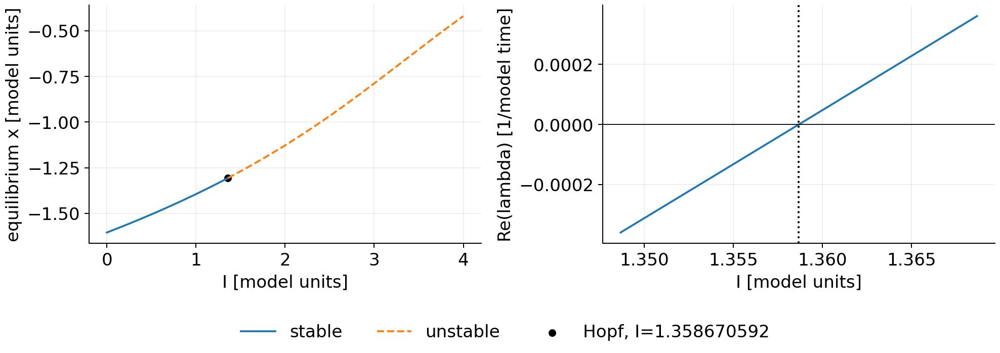

In [3]:
show_figure('figures/A_equilibria.png')

Full states, residuals and eigenvalues: [equilibria.csv](reproducibility/tables/equilibria.csv).

<a id="section-5"></a>

### A2. Stability and a refined critical point

$$A(x)=\begin{pmatrix}-3x^2+6x&1&-1\\-10x&-1&0\\0.024&0&-0.006\end{pmatrix}.$$

The maximum real eigenvalue crosses zero once along the investigated branch.
Brent refinement gives

$$\boxed{I_H=1.358670591812},\qquad \omega=0.0409059652.$$

The opposite-sign bracket is [1.3586705918117, 1.3586705918121], narrower than $10^{-6}$. This is numerical
localization for fixed coefficients, not a statistical confidence interval.
The critical state is -1.306267321, -7.531671566, 1.174930717. The spectrum has one negative real eigenvalue and
a simple nonzero imaginary conjugate pair; no zero eigenvalue occurs.

| delta_I | real | imag |
| --- | --- | --- |
| -0.001 | -13.9661 | 0 |
| -0.001 | -3.605e-05 | 0.040906 |
| -0.001 | -3.605e-05 | -0.040906 |
| -0.0001 | -13.963 | 0 |
| -0.0001 | -3.605e-06 | 0.040906 |
| -0.0001 | -3.605e-06 | -0.040906 |
| -1.000e-06 | -13.9626 | 0 |
| -1.000e-06 | -3.606e-08 | 0.040906 |
| -1.000e-06 | -3.606e-08 | -0.040906 |
| 0 | -13.9626 | 0 |
| 0 | 1.504e-16 | 0.040906 |
| 0 | 1.504e-16 | -0.040906 |
| 1.000e-06 | -13.9626 | 0 |
| 1.000e-06 | 3.606e-08 | 0.040906 |
| 1.000e-06 | 3.606e-08 | -0.040906 |
| 0.0001 | -13.9623 | 0 |
| 0.0001 | 3.606e-06 | 0.040906 |
| 0.0001 | 3.606e-06 | -0.040906 |
| 0.001 | -13.9591 | 0 |
| 0.001 | 3.606e-05 | 0.0409059 |
| 0.001 | 3.606e-05 | -0.0409059 |

The transverse crossing derivative is 0.03605521, using a centered current step
$10^{-5}$. With $\|q\|_2=1$, $p^Hq=1$, the first Hopf normal-form coefficient is
$l_1=0.01387674>0$, calculated as

$$l_1=\frac1{2\omega}\Re\langle p,C(q,q,\bar q)
-2B(q,A^{-1}B(q,\bar q))+B(\bar q,(2i\omega\mathbf1-A)^{-1}B(q,q))\rangle,$$

where $B(u,v)=((-6x_*+6)u_xv_x,-10u_xv_x,0)^T$ and
$C(u,v,w)=(-6u_xv_xw_x,0,0)^T$. This coefficient is not an attractor Lyapunov
exponent. These checks support a nondegenerate **subcritical Hopf bifurcation**:
the equilibrium loses stability as I increases and a small unstable cycle is
expected on its stable side. The unstable cycle and a cycle-fold location were
not continued in this study.

In [4]:
critical = json.loads((ROOT/'data/critical_point.json').read_text())
I_H = critical['I']
rows=[]
for delta in [-1e-6, 0., 1e-6]:
    spectrum=np.linalg.eigvals(cnm.jacobian(cnm.equilibrium(I_H+delta)))
    rows.append({'delta_I':delta,'maximum_real_part':spectrum.real.max(),
                 'imaginary_pair_frequency':abs(spectrum.imag).max()})
assert rows[0]['maximum_real_part'] < 0 < rows[-1]['maximum_real_part']
display(pd.DataFrame(rows))
print('Hopf coefficient:',critical['first_lyapunov_coefficient'])

,delta_I,maximum_real_part,imaginary_pair_frequency
0,-0.000001,-3.605521e-08,0.040906
1,0.000000,1.504398e-16,0.040906
2,0.000001,3.605522e-08,0.040906


Hopf coefficient: 0.013876737358888136


<a id="section-6"></a>

### A3. Maxima, interspike intervals and four sweep protocols

The grid $I=0,0.05,\ldots,4$ has 81 points. Every observation lasts 4000.
Transients are 6000 except at $I=1.30$ (12000) and $I=1.35$ (80000), where slow
decay invalidated the original short protocol. Forward and backward sweeps propagate
the actual final state; each independent run restarts from one prescribed IC.
Spikes are positive crossings of $x=0$, with within-step cubic Hermite localization.
Local maxima are positive-to-negative crossings of $\dot x$, including subthreshold
extrema; they are not selected by a membrane-potential threshold.

All 109 quiet tails among 324 records satisfy full-state distance below
$1.2\cdot10^{-10}$ and field residual below $4.8\cdot10^{-12}$.
Raw extrema in numerically flat tails ($x$ range $\le10^{-9}$) are retained but
are not drawn as an oscillatory branch. Rest is represented by A1's equilibrium
branch. Per-record diagnostics: [sweep_stationarity.csv](reproducibility/tables/sweep_stationarity.csv).

In [5]:
# The tail test uses all state coordinates, not only a spike count.
sweep = csv('sweep_stationarity.csv')
quiet = sweep[sweep.quiet_candidate]
assert quiet.quiet_stationarity_passed.all()
display(quiet.groupby('mode').agg(records=('I','size'),
    max_state_distance=('tail_max_state_distance','max'),
    max_field_residual=('tail_max_rhs_infinity_norm','max')))
print('Raw extrema remain saved even when a tail is numerically flat.')

,records,max_state_distance,max_field_residual
mode,,,
backward,27,3.196591e-12,4.440892e-14
forward,28,1.151135e-10,4.759748e-12
independent_ic1,27,3.045467e-12,4.440892e-14
independent_ic2,27,3.089967e-12,4.440892e-14


Raw extrema remain saved even when a tail is numerically flat.


**A3: four protocols; local maxima on the left and ISI on the right**

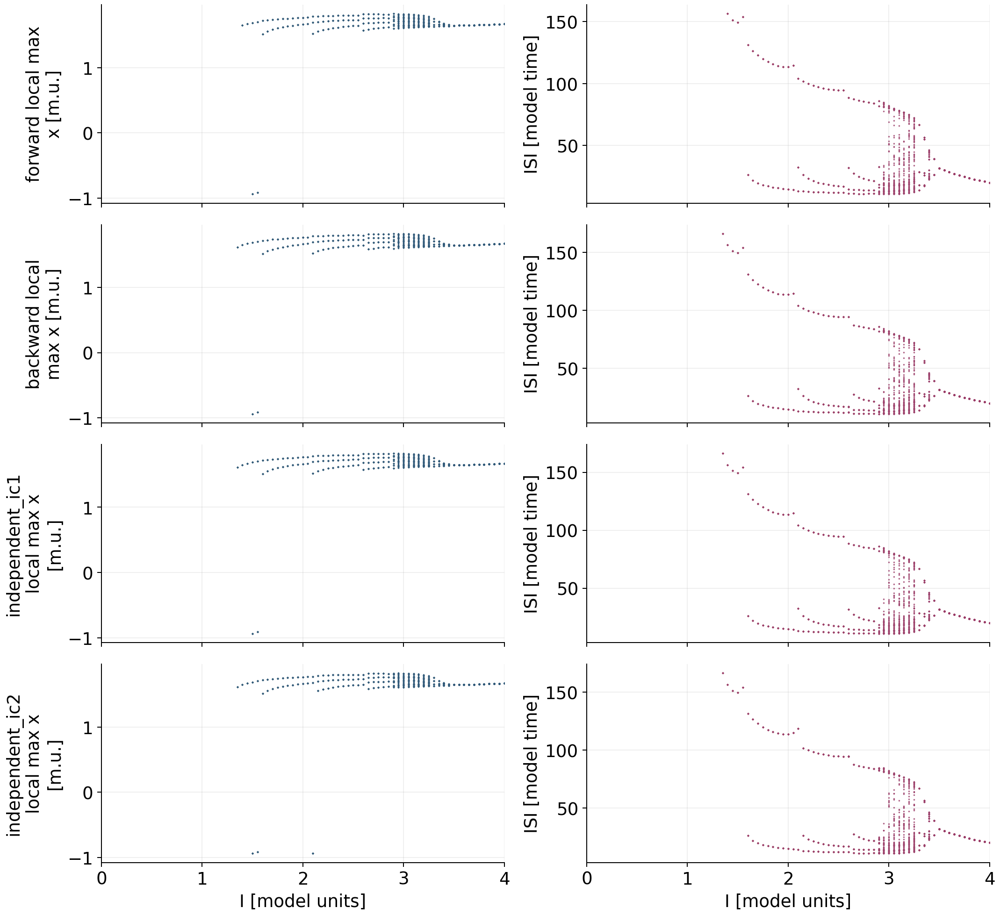

In [6]:
show_figure('figures/A_sweeps.png')

| protocol | largest I without spikes | smallest I with spikes |
| --- | --- | --- |
| backward | 1.3 | 1.35 |
| forward | 1.35 | 1.4 |
| independent_ic1 | 1.3 | 1.35 |
| independent_ic2 | 1.3 | 1.35 |

The forward sweep remains quiet at 1.35 and spikes at 1.4; the other protocols
already spike at 1.35. These are width-0.05 grid brackets, not refined bifurcation
values. A refined region $I\in[2.8,3.4]$ uses 31 points at step 0.02,
transient 10000 and observation 12000; it reveals irregular bands and periodic windows.

**A3: refined regime-transition region**

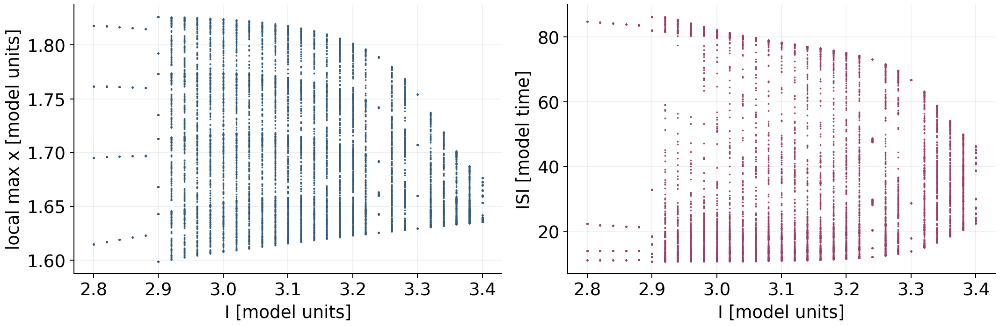

In [7]:
show_figure('figures/A_transition_zoom.png')

Near onset, separate 40000-transient runs include the prescribed ICs and small
perturbations of the known equilibrium:

| I | initial | spikes | range_x | distance_to_eq |
| --- | --- | --- | --- | --- |
| 1.33 | ic1 | 34 | 3.23837 | 0.146804 |
| 1.33 | ic2 | 34 | 3.23977 | 1.05603 |
| 1.33 | near_eq | 0 | 0 | 3.140e-12 |
| 1.358 | ic1 | 36 | 3.25005 | 0.719986 |
| 1.358 | ic2 | 36 | 3.25003 | 1.35843 |
| 1.358 | near_eq | 0 | 5.500e-07 | 2.992e-06 |
| 1.359 | ic1 | 37 | 3.24939 | 2.06322 |
| 1.359 | ic2 | 37 | 3.24983 | 3.62316 |
| 1.359 | near_eq | 0 | 2.499e-06 | 1.570e-05 |
| 1.37 | ic1 | 37 | 3.25062 | 3.05541 |
| 1.37 | ic2 | 37 | 3.25087 | 4.17585 |
| 1.37 | near_eq | 37 | 3.25213 | 1.52729 |

At $I=1.33<I_H$, the prescribed ICs oscillate while a state near the equilibrium
converges to rest, demonstrating coexistence. Small amplitudes after 40000 near
Hopf do not establish stability; two perturbation runs were extended to $10^6$:

| I | transient | spikes | range_x | distance_to_eq |
| --- | --- | --- | --- | --- |
| 1.358 | 1000000 | 0 | 9.822e-12 | 6.248e-11 |
| 1.359 | 1000000 | 37 | 3.24985 | 1.80474 |

Perturbations decay below Hopf and escape above it. Activity onset in a sweep thus
need not coincide with equilibrium destabilization. See
[onset_statistics.csv](reproducibility/tables/onset_statistics.csv) and [onset_extended.csv](reproducibility/tables/onset_extended.csv).

<a id="section-7"></a>

### A4. Independent dynamical classification

In [8]:
# Independent classification is read before any ordinal result.
lyapunov = csv('lyapunov.csv')
assert (lyapunov[lyapunov.regime=='chaotic'].lambda1 > .005).all()
display(lyapunov[['regime','h','lambda1','lambda2','lambda3','sum_minus_divergence']])
independent = json.loads((ROOT/'data/independent_hr_results.json').read_text())
print('Independent DOP853 chaotic exponent:', independent['chaotic']['lambda1'])
print('Every independent 1000-time block positive:', independent['chaotic']['block_lambda1_min']>0)

,regime,h,lambda1,lambda2,lambda3,sum_minus_divergence
0,spiking,0.04,0.000034,-0.041823,-6.547610,0.000979
1,spiking,0.02,0.000034,-0.041822,-6.548551,0.000053
2,spiking,0.01,0.000034,-0.041822,-6.548602,0.000003
3,bursting,0.04,0.000005,-0.004639,-10.913708,0.012788
4,bursting,0.02,0.000005,-0.004639,-10.925872,0.000626
5,bursting,0.01,0.000005,-0.004639,-10.926463,0.000035
6,chaotic,0.04,0.013198,0.000026,-8.413811,0.002756
7,chaotic,0.02,0.013477,-0.000006,-8.409032,0.000143
8,chaotic,0.01,0.013535,-0.000004,-8.408614,0.000008


Independent DOP853 chaotic exponent: 0.012496391597793522
Every independent 1000-time block positive: True


**A4: time series, full-state phase portraits and ISI return plots**

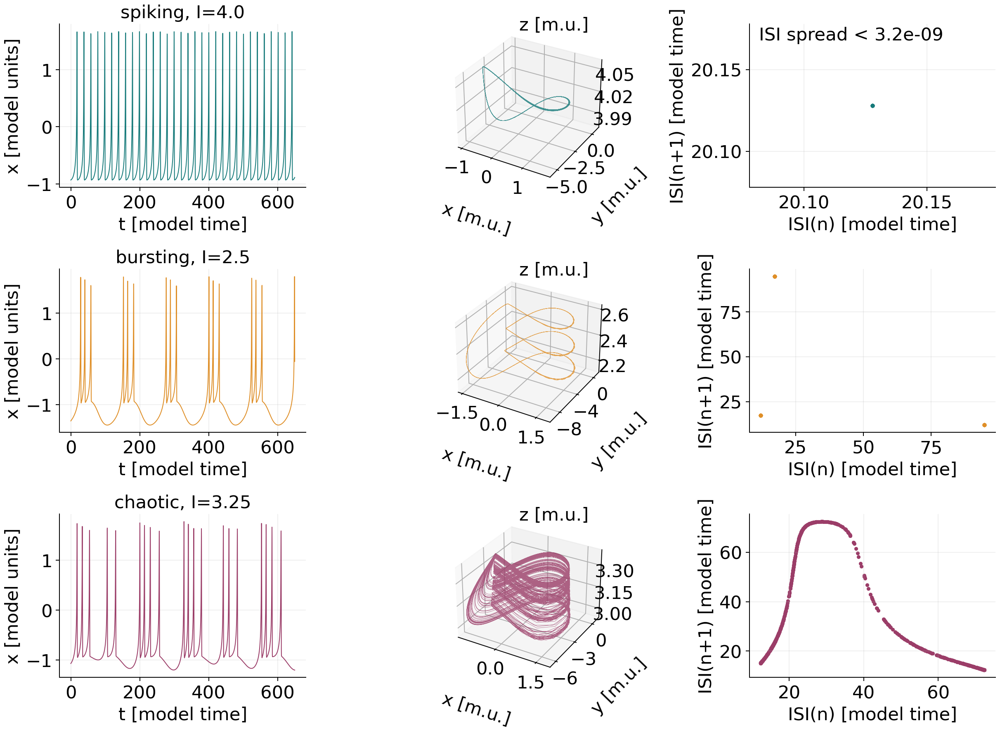

In [9]:
show_figure('figures/A_selected_regimes.png')

The regular spiking section returns to one full-state point; bursting returns to
three, with a full period equal to three ISIs. All three state components are
checked. No shift by 1-12 spikes closes the chaotic candidate comparably well.

| regime | p_spikes | mean_period | std_period | section_median_error | section_max_error |
| --- | --- | --- | --- | --- | --- |
| spiking | 1 | 20.1279 | 1.102e-09 | 2.092e-09 | 3.043e-09 |
| bursting | 3 | 124.106 | 1.183e-09 | 2.213e-09 | 4.866e-09 |
| chaotic | 4 | 134.411 | 19.0913 | 0.0636762 | 0.374202 |

The variational equation $\dot Q=A(s(t))Q$ is integrated jointly with the state by
RK4. Modified Gram-Schmidt orthogonalization occurs every unit of model time.
After 10000 warm-up, accumulated spectra are observed for 80000, with saved 1000-time
blocks. Steps $0.04,0.02,0.01$ and chaotic QR intervals $0.5,1,2$ are compared.

| regime | h | lambda1 | lambda2 | lambda3 | first_half_mean | second_half_mean | sum_minus_divergence |
| --- | --- | --- | --- | --- | --- | --- | --- |
| spiking | 0.04 | 3.390e-05 | -0.0418228 | -6.54761 | 4.126e-05 | 2.654e-05 | 0.000978763 |
| spiking | 0.02 | 3.436e-05 | -0.0418219 | -6.54855 | 4.166e-05 | 2.706e-05 | 5.283e-05 |
| spiking | 0.01 | 3.438e-05 | -0.0418218 | -6.5486 | 4.168e-05 | 2.709e-05 | 3.070e-06 |
| bursting | 0.04 | 4.837e-06 | -0.00463916 | -10.9137 | 4.290e-05 | -3.323e-05 | 0.0127878 |
| bursting | 0.02 | 4.877e-06 | -0.00463909 | -10.9259 | 4.308e-05 | -3.333e-05 | 0.000625725 |
| bursting | 0.01 | 4.880e-06 | -0.00463908 | -10.9265 | 4.309e-05 | -3.333e-05 | 3.463e-05 |
| chaotic | 0.04 | 0.0131977 | 2.646e-05 | -8.41381 | 0.0132244 | 0.013171 | 0.00275643 |
| chaotic | 0.02 | 0.013477 | -5.766e-06 | -8.40903 | 0.0132273 | 0.0137268 | 0.000142809 |
| chaotic | 0.01 | 0.0135346 | -3.593e-06 | -8.40861 | 0.0134078 | 0.0136614 | 8.146e-06 |

**A4: largest-exponent convergence**

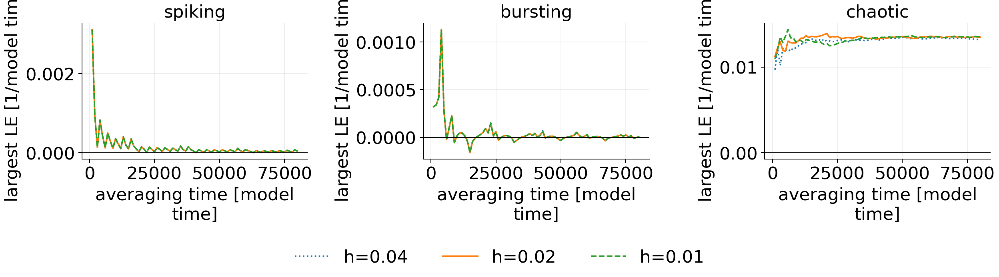

In [10]:
show_figure('figures/A_lyapunov_convergence.png')

An autonomous limit cycle has a neutral direction; tiny positive finite-time
estimates for periodic signals do not imply chaos. At $I=3.25$, the largest exponent
remains positive, the second is near zero and the third negative. Both half-record
averages are positive at every step. Together with bounded irregular motion and
a nonperiodic section, this supports deterministic chaos numerically.
The sum is checked against mean divergence (`sum_minus_divergence`); the most
negative exponent is less accurate at $h=0.04$. Sign conclusions use the finer steps.
For rest at $I=1$: $\|s_{end}-s_*\|_2=6.71e-13$, $\max x-\min x=0$, $\|f(s_{end})\|_\infty=4.44e-14$.

### Independent solver and periodic-orbit verification

A separately written vector field/Jacobian is checked by complex-step differentiation
(maximum error 1.78e-15). An independent 80-digit Decimal Routh-Hurwitz calculation
$a_1a_2=a_3$ gives $I_H=1.358670591811940834\ldots$, agreeing with A2.
This arithmetic precision does not represent uncertainty in biological parameters.
Full-state shooting on $x=0$ refines periodic orbits; independent DOP853 verifies them:

| regime | period | closure residual | neutral multiplier error | transverse multiplier |
| --- | --- | --- | --- | --- |
| spiking | 20.1279 | 2.245e-12 | 1.162e-11 | 0.431018 |
| bursting | 124.106 | 5.987e-13 | 5.274e-13 | -0.562256 |

The neutral multiplier is near 1 and the transverse multiplier has modulus below 1.
Strong contraction is ill-conditioned in a raw monodromy eigendecomposition, so its
logarithm is saved using Liouville's formula. Perturbing the period by $\pm10^{-5}$
increases closure residuals to $7\ldots9\cdot10^{-6}$.
Independent DOP853 plus Householder QR gives chaotic $\lambda_1=0.012496$
over 5000 after warm-up, with all five 1000-time blocks positive (0.00820-0.01688).
It verifies sign and scale, rather than exact agreement with another trajectory's
80000-time mean. See [independent_hr_checks.csv](reproducibility/tables/independent_hr_checks.csv).

### Library reference calculations

Standard calculations are also performed with established research packages.
The [ordpy implementation](https://arthurpessa.github.io/ordpy/) computes ordinal
distributions, normalized permutation entropy and Jensen-Shannon complexity from
the actual scalar recordings. Exact lexicographic ranks implement the stated
(value, time-index) tie rule without random jitter. This includes rounded ISIs.
Across 66 signal/settings combinations, every full-alphabet count agrees;
the maximum absolute H,C difference is 1.17e-15. The notebook computes its principal
H,C comparison directly through ordpy. See `tables/library_ordinal_validation.csv`.

[JiTCODE](https://jitcode.readthedocs.io/) forms the HR tangent equations by
symbolic automatic differentiation and integrates them with SciPy's adaptive
DOP853 backend. Its own QR implementation estimates all three model exponents.
The initial tangent basis is the identity, with transient 10000, observation 30000
and QR every one model-time unit. Two tolerance settings are compared below.
All state coordinates, local growth rates and tangent bases are retained.

| regime | rtol | lambda1 | lambda2 | lambda3 | block_min | block_max |
| --- | --- | --- | --- | --- | --- | --- |
| spiking | 1.000e-08 | 7.734e-05 | -0.0418381 | -6.54903 | -0.000499189 | 0.00042159 |
| spiking | 1.000e-10 | 7.734e-05 | -0.0418381 | -6.54903 | -0.000499189 | 0.00042159 |
| bursting | 1.000e-08 | 1.253e-05 | -0.00462463 | -10.9237 | -0.000513711 | 0.000684805 |
| bursting | 1.000e-10 | 1.253e-05 | -0.00462463 | -10.9237 | -0.000513711 | 0.000684805 |
| chaotic | 1.000e-08 | 0.0133477 | 5.253e-05 | -8.41465 | 0.0116681 | 0.0149931 |
| chaotic | 1.000e-10 | 0.0141381 | -2.040e-05 | -8.40323 | 0.0129453 | 0.0151751 |

The periodic estimates remain compatible with zero. Both chaotic runs have
positive means and positive 5000-unit block means; their different finite-time
values reflect different chaotic trajectories and do not establish accuracy in
the last displayed digits. Block ranges are descriptive, not independent-sample
confidence intervals. This verifies the sign and scale independently of the
fixed-step code; it does not strengthen the uncertain limiting D0/D2 claims.

SciPy already supplies adaptive ODE solvers, root finding, spatial trees and linear
algebra throughout the study. Explicit custom layers enforce the assignment's
Theiler windows, scaling diagnostics, and convergence experiments. The hybrid
Izhikevich tangent calculation additionally requires event saltation, which a
generic smooth-flow exponent routine cannot replace. Exact package versions:
ordpy 1.2.2, jitcode 1.7.3, jitcxde_common 1.5.6, symengine 0.14.1, scipy 1.16.3.

In [11]:
# These are actual independent package calculations, not labels for the custom code.
library = csv('library_lyapunov_validation.csv')
for row in library.itertuples():
    record = np.load(ROOT/'data/library_validation'/f'{row.regime}_rtol{row.rtol:g}.npz')
    np.testing.assert_allclose(record['local_exponents'].mean(axis=0),
                               [row.lambda1,row.lambda2,row.lambda3], atol=1e-13)
assert (library.loc[library.regime=='chaotic','block_min']>0).all()
assert library.loc[library.regime!='chaotic','lambda1'].abs().max()<2e-4
display(library)
print('JiTCODE forms the tangent equations automatically and uses SciPy dop853.')
display(csv('library_ordinal_validation.csv').groupby('signal')[['H_difference','C_difference']].max())

,regime,I,rtol,transient,duration,lambda1,lambda2,lambda3,block_min,block_max
0,spiking,4.00,1.000000e-08,10000.0,30000.0,0.000077,-0.041838,-6.549031,-0.000499,0.000422
1,spiking,4.00,1.000000e-10,10000.0,30000.0,0.000077,-0.041838,-6.549031,-0.000499,0.000422
2,bursting,2.50,1.000000e-08,10000.0,30000.0,0.000013,-0.004625,-10.923716,-0.000514,0.000685
3,bursting,2.50,1.000000e-10,10000.0,30000.0,0.000013,-0.004625,-10.923720,-0.000514,0.000685
4,chaotic,3.25,1.000000e-08,10000.0,30000.0,0.013348,0.000053,-8.414650,0.011668,0.014993
5,chaotic,3.25,1.000000e-10,10000.0,30000.0,0.014138,-0.000020,-8.403232,0.012945,0.015175


JiTCODE forms the tangent equations automatically and uses SciPy dop853.


,H_difference,C_difference
signal,,
HH_DC,0.0,2.775558e-16
HH_DC_rounded_ISI,0.0,0.000000e+00
HH_strong,0.0,3.330669e-16
HH_strong_rounded_ISI,0.0,0.000000e+00
HH_weak,0.0,2.775558e-16
Izh_DC,0.0,2.775558e-16
Izh_DC_rounded_ISI,0.0,0.000000e+00
Izh_strong,0.0,1.165734e-15
Izh_strong_rounded_ISI,0.0,2.220446e-16


<a id="section-8"></a>

## B. Scalar reconstruction and attractor dimensions

<a id="section-9"></a>

### B1. Preprocessing, ACF, mutual information and false neighbors

Only post-transient $x_n$ enters B. A single mean and standard deviation standardize
each series; no signal smoothing, hidden coordinates or phase fitting is used.
Fixed nonsingular affine scaling preserves theoretical dimensions.

$$X_i^{(m)}=(x_i,x_{i+k},\ldots,x_{i+(m-1)k}),\quad
0\le i<N-(m-1)k.$$

The ACF uses FFT and a common zero-lag normalization; its candidate is the first
nonpositive lag. Mutual information uses 16/32/64 equal-width histogram bins and
marginals from the same joint histogram. Only the diagnostic MI curve is smoothed
(Gaussian sigma 1 sample, prominence 0.005 nat) to identify a pronounced first
minimum; raw curves are retained. ACF decorrelation and MI dependence need not agree.

| regime | ACF lag | first MI lag | initial selected lag | tau | initial m | W samples | FNN |
| --- | --- | --- | --- | --- | --- | --- | --- |
| spiking | 16 | 37 | 37 | 7.4 | 3 | 148 | 0.00491667 |
| bursting | 159 | 54 | 125 | 25 | 5 | 500 | 0.00266667 |
| chaotic | 124 | 164 | 164 | 32.8 | 8 | 656 | 0.0883333 |

In [12]:
# Recompute FNN from x alone, with the frozen short-delay settings.
raw = np.load(ROOT/'data/chaotic.npz')
x_clean = raw['state'][:-1, 0]
x = cnm.standardize(x_clean)
fnn = cnm.false_nearest(x, 10, 8, 656, 12000)
assert fnn[5, 1] < .01
display(pd.DataFrame(fnn, columns=['m','FNN_fraction','usable','omitted']))
print('Only scalar potential entered this estimator.')

,m,FNN_fraction,usable,omitted
0,1.0,0.954917,12000.0,0.0
1,2.0,0.033667,12000.0,0.0
2,3.0,0.008083,12000.0,0.0
3,4.0,0.003333,12000.0,0.0
4,5.0,0.002000,12000.0,0.0
5,6.0,0.000500,12000.0,0.0
6,7.0,0.000917,12000.0,0.0
7,8.0,0.000583,12000.0,0.0


Only scalar potential entered this estimator.


**B1: original ACF, MI and FNN diagnostics**

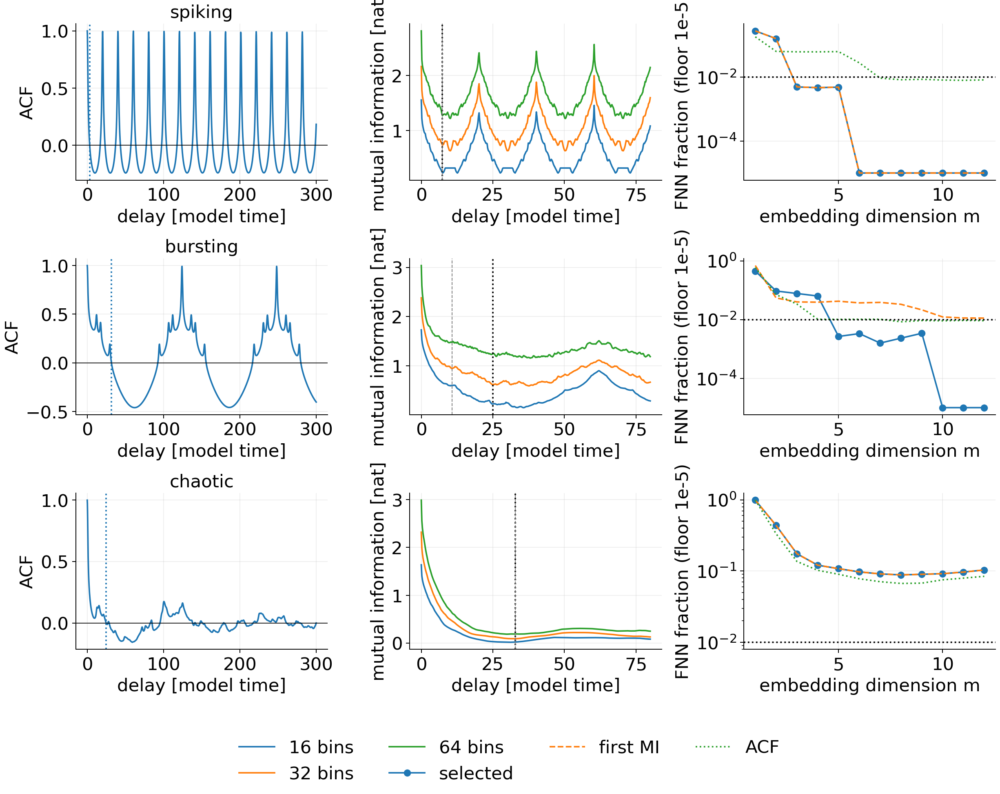

In [13]:
show_figure('figures/B_reconstruction_diagnostics.png')

FNN uses the same eligible start indices for m and m+1 and the same nearest neighbor.
Neighbors with $|i-j|\le W$ are excluded. A neighbor is false if
$|x_{i+mk}-x_{j+mk}|/r_m>10$ or $r_{m+1}/\sigma_x>2$.
Zero distances are handled explicitly. Up to 12000 indices cover the whole record;
W remains in original sample units. The operational criterion is below 1% FNN,
sustained at higher m. The bursting first-MI choice fails; its third MI32 minimum
$k=125$ produces sustained FNN below 1% from m=5. Initial candidates remain visible.

**B1: initial delay projections, including the unsuccessful chaotic first-MI choice**

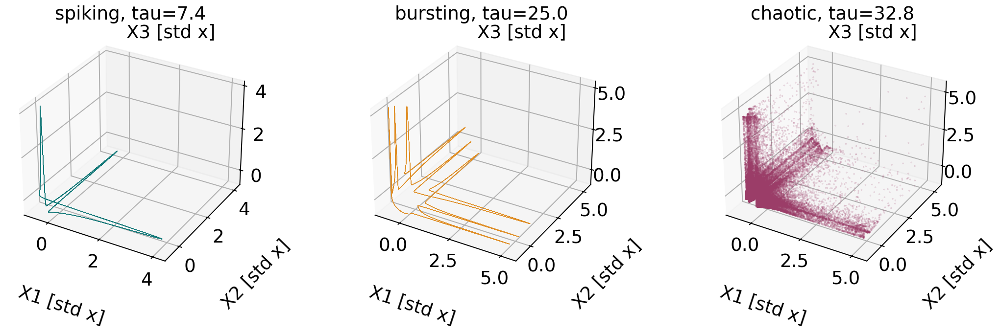

In [14]:
show_figure('figures/B_reconstructed_attractors.png')

For chaos, $k=164$ ($\tau=32.8$) still gives about 8.8% FNN at trial m=8; that
initial embedding is unconfirmed. Shorter candidates k=8,10,12, tested with the
same criteria and W=656, support a conservative common m=6. At k=10, adjacent
correlation is about 0.355 and covariance condition number about 3.73, excluding
a simple near-diagonal collapse as the explanation of improved FNN.

| lag | tau | m | W | FNN | usable |
| --- | --- | --- | --- | --- | --- |
| 8 | 1.6 | 6 | 656 | 0 | 12000 |
| 10 | 2 | 6 | 656 | 0.0005 | 12000 |
| 12 | 2.4 | 6 | 656 | 0.00775 | 12000 |
| 124 | 24.8 | 6 | 656 | 0.07775 | 12000 |
| 164 | 32.8 | 6 | 656 | 0.0973333 | 12000 |

**B1: shorter delays, FNN and covariance conditioning**

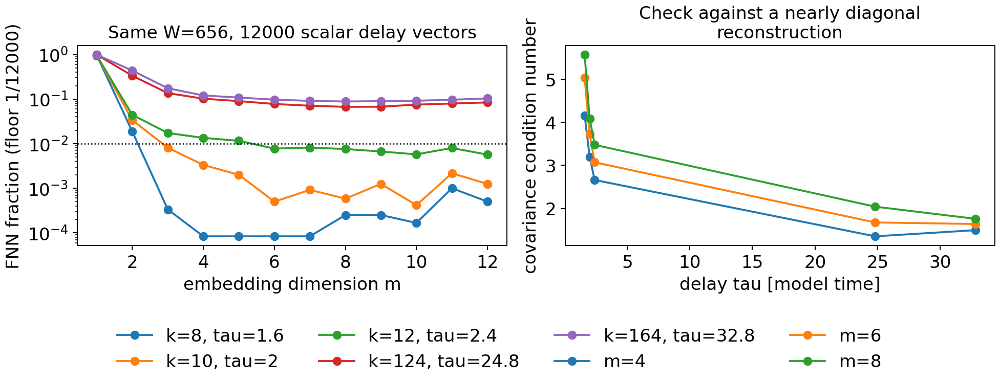

In [15]:
show_figure('figures/B_refined_reconstruction.png')

**B1: initial MI and revised chaotic delay geometry**

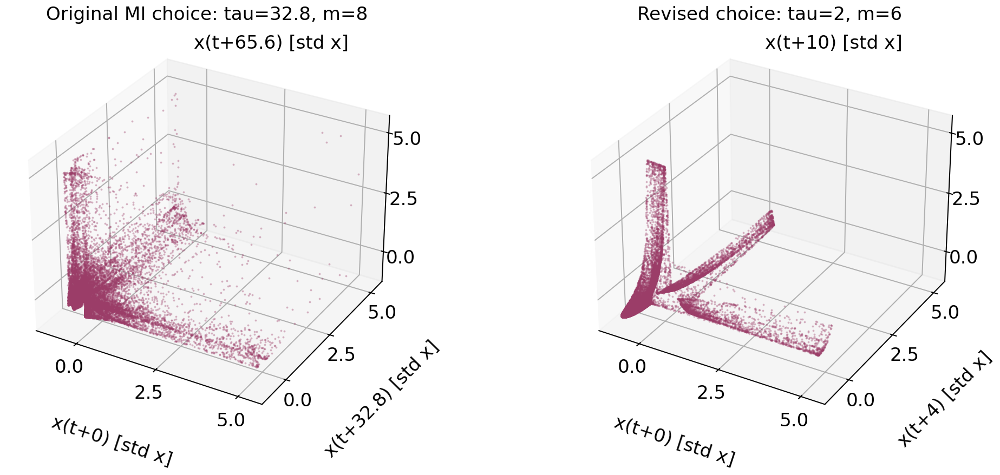

In [16]:
show_figure('figures/B_refined_attractor.png')

The revised chaotic analyses use k=10,m=6,W=656 (physical delay 2, exclusion time
131.2). The original justified regular-signal choices remain. These diagnostics
support unfolding but do not prove an embedding theorem for the finite recording.
Settings: [settings.json](reproducibility/data/reconstruction_refinement/settings.json).

<a id="section-10"></a>

### B2. Correlation dimension and temporal dependence

For an invariant measure, $D_2=\lim_{r\downarrow0}\ln C(r)/\ln r$ when the limit exists.
The Grassberger-Procaccia estimate uses Euclidean distances and an explicit Theiler
exclusion:

$$\widehat C_m(r;W)=\frac{\sum_{a<b,\ i_b-i_a>W}
\mathbf1\{\|X_{i_a}-X_{i_b}\|\le r\}}
{\#\{a<b:i_b-i_a>W\}}.$$

`cKDTree.count_neighbors` is converted to unordered pairs, with diagonal and temporal
pairs removed from numerator and denominator. This exact sum over selected vectors
is checked against brute force. Original calculations use up to 12000 vectors;
refined calculations use up to 16000. Radius is shown as $r/\sqrt m$ in standardized
scalar units. Fits require at least 200 close pairs and $C<0.15$.

In [17]:
# Recompute the selected GP sum and fit, not just a saved figure.
from cnm import correlation_sum, fit_scaling
reference = np.load(ROOT/'data/reconstruction_refinement/gp_lag10_m6.npz')
gp = correlation_sum(x, 6, 10, 656, reference['r'], maxpoints=16000)
fit = fit_scaling(gp, .001*np.sqrt(6), .01*np.sqrt(6))
expected = csv('reconstruction_refinement_gp.csv')
expected = expected[(expected['case']=='lag10_m6') & (expected.nominal_lower==.001)].iloc[0]
assert abs(fit['estimate']-expected.estimate) < 1e-9
display(pd.DataFrame([fit]))
print('This is a finite-scale slope, not a confidence interval for a limiting dimension.')

,estimate,intercept,r2,nscales,rmin,rmax,min_pairs,local_min,local_max
0,1.876694,0.324987,0.999955,31,0.002604,0.023886,2437,1.825235,1.973529


This is a finite-scale slope, not a confidence interval for a limiting dimension.


**B2: original correlation sums and local slopes; chaotic first-MI results are diagnostic only**

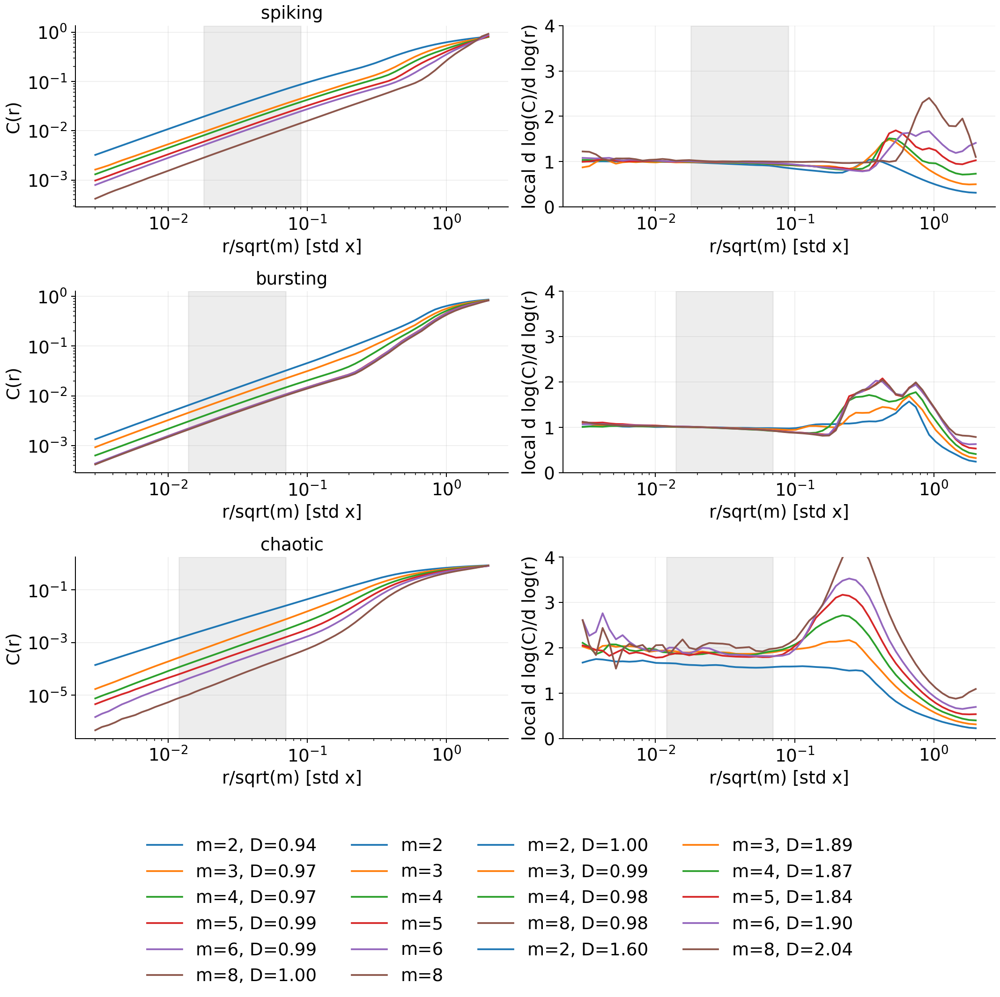

In [18]:
show_figure('figures/B_correlation_dimension.png')

| regime | m | estimate | local_min | local_max |
| --- | --- | --- | --- | --- |
| spiking | 2 | 0.939333 | 0.873643 | 0.979332 |
| spiking | 3 | 0.970337 | 0.923751 | 0.988296 |
| spiking | 4 | 0.974586 | 0.933276 | 1.00038 |
| spiking | 5 | 0.985604 | 0.950915 | 1.00728 |
| spiking | 6 | 0.988077 | 0.957325 | 1.00409 |
| spiking | 8 | 1.00437 | 0.996952 | 1.02322 |
| bursting | 2 | 0.995961 | 0.982662 | 1.01008 |
| bursting | 3 | 0.988968 | 0.959243 | 1.01152 |
| bursting | 4 | 0.980172 | 0.926316 | 1.01233 |
| bursting | 5 | 0.986816 | 0.936771 | 1.01983 |
| bursting | 6 | 0.985718 | 0.93493 | 1.02137 |
| bursting | 8 | 0.983727 | 0.93191 | 1.01454 |

The revised reconstruction compares neighboring delays, m=3,4,6,8,
W=0,328,656,1312,2624, partial and doubled records, and neighboring radius intervals.
The main interval is $0.001\le r/\sqrt m\le0.01$; the k=10,m=6 fit is 1.8767, local slopes 1.825-1.974, minimum 2437 close pairs.

**B2: refined correlation sums, local slopes and fitting bands**

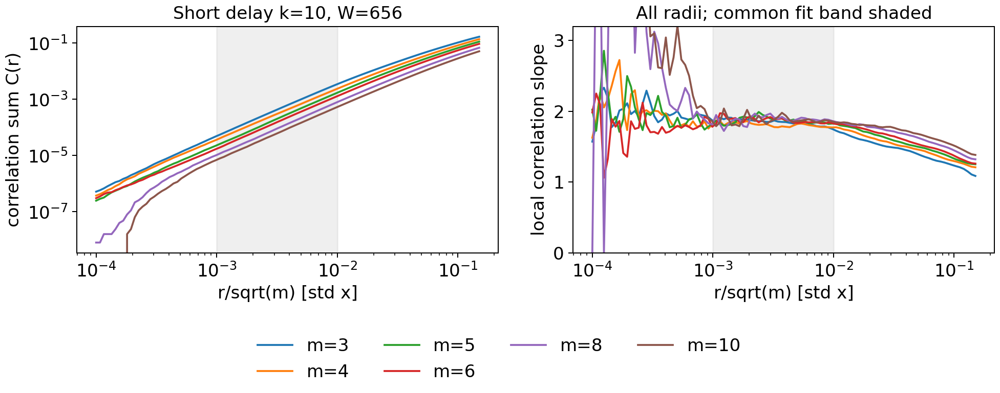

In [19]:
show_figure('figures/B_refined_gp.png')

**B2: sensitivity to delay, W, record length and radius band**

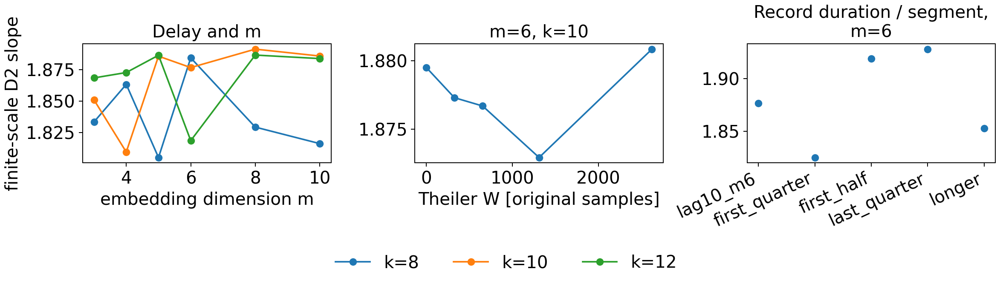

In [20]:
show_figure('figures/B_refined_gp_sensitivity.png')

| varied | estimate_min | estimate_max | local_min | local_max | comparisons |
| --- | --- | --- | --- | --- | --- |
| N | 1.82511 | 1.92789 | 1.74197 | 2.10904 | 4 |
| W | 1.87294 | 1.88084 | 1.823 | 1.98952 | 4 |
| lag at m=6 | 1.81855 | 1.88444 | 1.76113 | 1.97353 | 3 |

These are sensitivity envelopes, not confidence intervals. Curves across radii and
embeddings reuse the same observations; high regression R-squared cannot establish
an asymptotic dimension. The results show geometry more complex than a smooth cycle
and an effective slope around 1.9. An exact limiting D2 is not established.
All 130 fits: [reconstruction_refinement_gp.csv](reproducibility/tables/reconstruction_refinement_gp.csv).

<a id="section-11"></a>

### B3. Capacity dimension and incomplete coverage

Capacity dimension is $D_0=\lim_{\varepsilon\downarrow0}\ln N(\varepsilon)/\ln(1/\varepsilon)$ when the limit exists.
Point box-counting counts distinct cells $\lfloor(X-b)/\varepsilon\rfloor$.
The original study compares m=3,4,5, lengths N/4,N/2,N and four grid shifts
0,0.25,0.5,0.75 cell widths, using the same scalar normalization in every coordinate.
The regular spiking slope is consistent with a curve:

In [21]:
# A direct point/path comparison on the same scalar-delay geometry.
from reconstruction_refinement import occupied_boxes
vectors = cnm.embed(x, 6, 10)
rows=[]
for eps in [.1, .2, .4]:
    points=occupied_boxes(vectors, eps, curve=False)
    path=occupied_boxes(vectors, eps, curve=True)
    assert path >= points
    rows.append({'epsilon':eps,'point_cells':points,'polygonal_path_cells':path})
display(pd.DataFrame(rows))
display(csv('reconstruction_refinement_summary_sampling.csv').query('m == 6 and tau == 2'))

,epsilon,point_cells,polygonal_path_cells
0,0.1,6784,9413
1,0.2,2190,2507
2,0.4,566,588


,case,m,tau,dt,method,estimate_min,estimate_max,local_min,local_max,comparisons
16,matched_dense_path,6,2.0,0.005,curve,1.877919,1.889174,1.083971,2.685425,2
17,matched_dense_path,6,2.0,0.005,points,1.864191,1.871497,1.083167,2.656277,2
18,matched_dense_path,6,2.0,0.010,curve,1.877751,1.888998,1.083971,2.685425,2
19,matched_dense_path,6,2.0,0.010,points,1.853642,1.865285,1.087877,2.631907,2
20,matched_dense_path,6,2.0,0.040,curve,1.879246,1.888773,1.079692,2.685425,2
21,matched_dense_path,6,2.0,0.040,points,1.784941,1.796022,1.078711,2.539367,2
22,matched_dense_path,6,2.0,0.200,curve,1.903915,1.914845,1.098570,2.660395,2
23,matched_dense_path,6,2.0,0.200,points,1.545457,1.575027,0.998062,2.418947,2


**B3: original point box-counting and fitting bands**

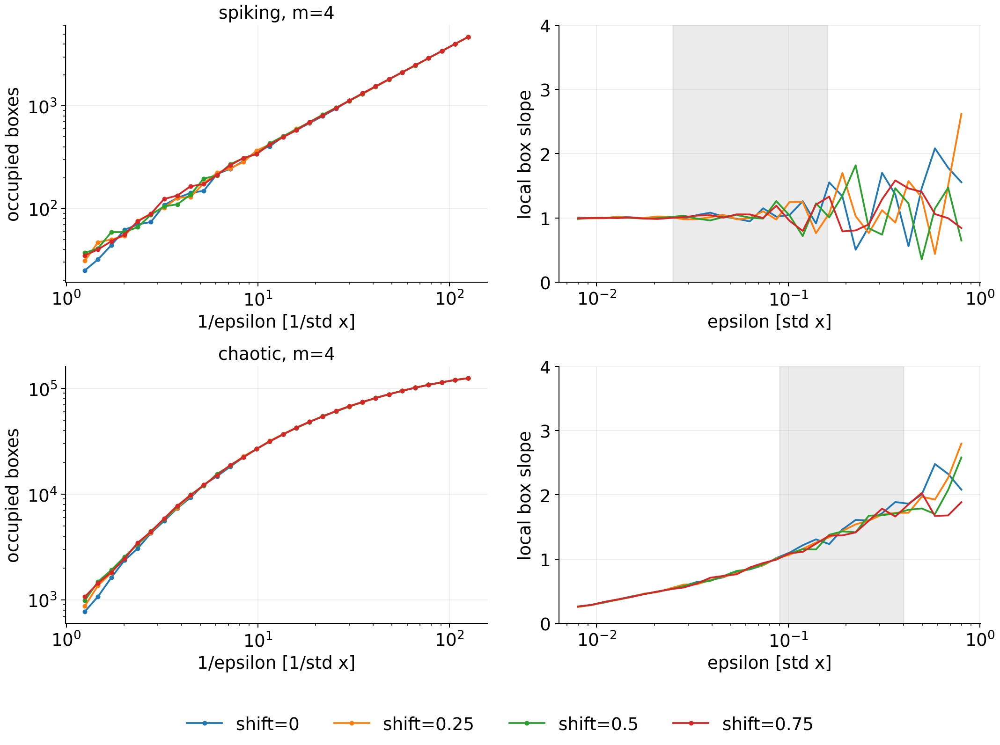

In [22]:
show_figure('figures/B_capacity_dimension.png')

| m | record_N | min | max |
| --- | --- | --- | --- |
| 3 | 37500 | 1.04477 | 1.09469 |
| 3 | 75000 | 1.04486 | 1.09411 |
| 3 | 150000 | 1.04564 | 1.09544 |
| 4 | 37500 | 1.00776 | 1.04606 |
| 4 | 75000 | 1.01582 | 1.04824 |
| 4 | 150000 | 1.01701 | 1.05046 |
| 5 | 37500 | 0.996728 | 1.01975 |
| 5 | 75000 | 1.00809 | 1.02392 |
| 5 | 150000 | 1.00998 | 1.02683 |

For chaos, original first-MI m=4 point fits give 1.410-1.452, below the correlation
estimate. The inequality $D_2\le D_0$ concerns limiting dimensions; its violation
by finite fits signals inadequate coverage or scales. The failed attempt is retained,
and intervals are not tuned to force agreement.
A separate estimator counts all cells crossed by segments joining consecutive scalar
delay vectors. This covers a polygonal path, adds no independent observations and
uses no hidden states. Exact traversal is tested on analytic lines, boundaries and
mixed-direction corners. Every finite polyline has limiting dimension 1; only its
resolved intermediate-scale behavior is examined here.

**B3: points versus polygonal paths, record length, embedding and grid origin**

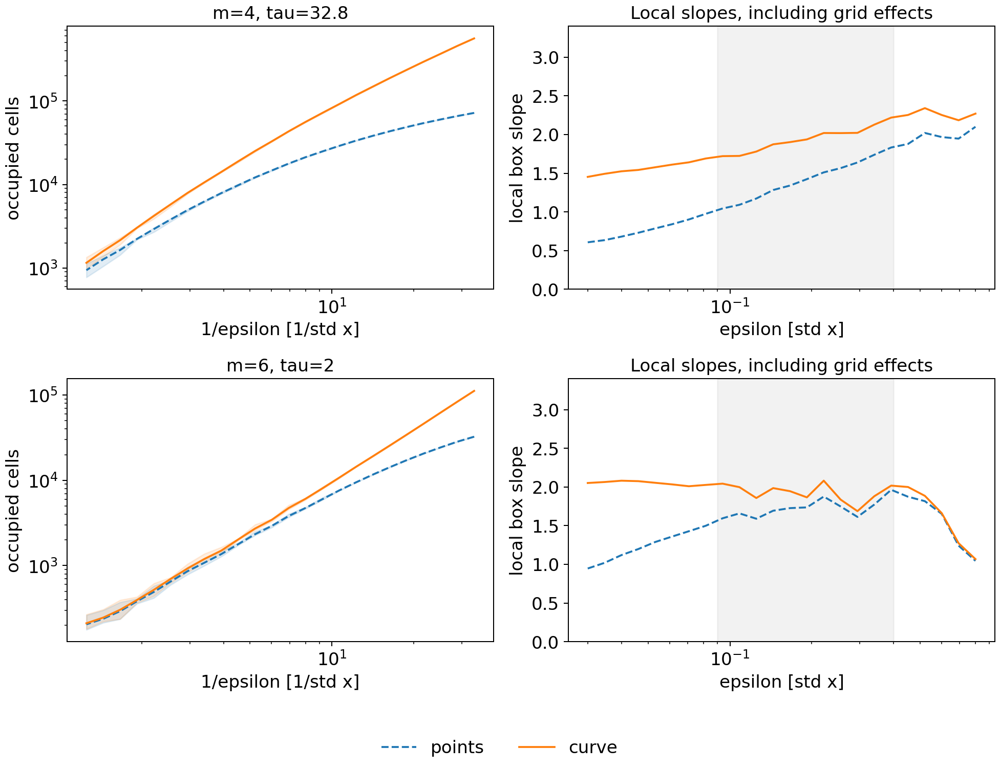

In [23]:
show_figure('figures/B_refined_capacity.png')

For k=10,m=6 on $0.09\le\varepsilon\le0.4$:

| case | dt | method | estimate_min | estimate_max |
| --- | --- | --- | --- | --- |
| main | 0.2 | curve | 1.87433 | 1.94097 |
| main | 0.2 | points | 1.68877 | 1.74657 |
| main_finer | 0.04 | curve | 1.84286 | 1.90542 |
| main_finer | 0.04 | points | 1.7931 | 1.86204 |
| main_longer | 0.2 | curve | 1.88183 | 1.94899 |
| main_longer | 0.2 | points | 1.74961 | 1.80732 |

A single dense trajectory uses h=0.0025, observation step 0.005, transient 10000
and observation 10000. All states are retained; only x is analyzed. Exact subsamples
at 0.01,0.04,0.2 isolate observation density from changes in the chaotic orbit,
while preserving physical delay and normalization. At m=6,tau=2:

| dt | method | estimate_min | estimate_max |
| --- | --- | --- | --- |
| 0.005 | curve | 1.87792 | 1.88917 |
| 0.005 | points | 1.86419 | 1.8715 |
| 0.01 | curve | 1.87775 | 1.889 |
| 0.01 | points | 1.85364 | 1.86528 |
| 0.04 | curve | 1.87925 | 1.88877 |
| 0.04 | points | 1.78494 | 1.79602 |
| 0.2 | curve | 1.90392 | 1.91485 |
| 0.2 | points | 1.54546 | 1.57503 |

**B3: one dense trajectory and its exact subsamples**

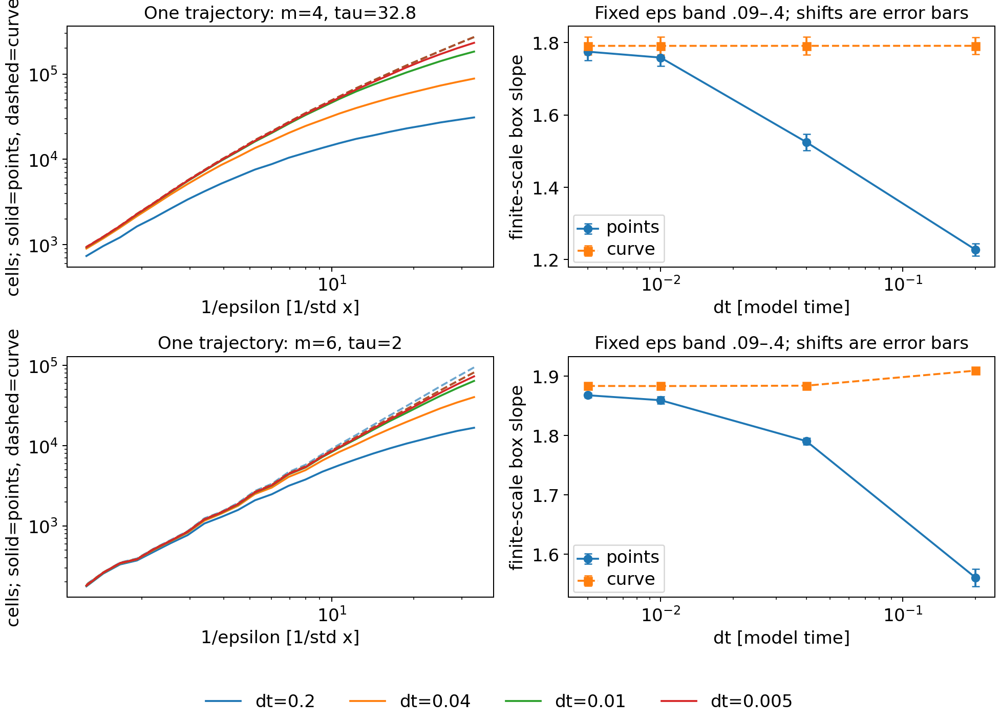

In [24]:
show_figure('figures/B_refined_sampling.png')

Point estimates approach path estimates as observation becomes denser. Path fits
at steps 0.005 and 0.01 nearly agree; step 0.2 has a shift around 0.025.
The maximum dense delay-path step is about 0.052 scalar standard deviations, below
the minimum fitted cell width 0.09. This checks sampling resolution; finite duration
and transverse coverage remain limitations. Wide local-slope variation prevents
interpreting the mean slope near 1.9 as an exact limiting capacity dimension.

<a id="section-12"></a>

### B4. Frozen-protocol validation and interpretation

After exploratory selection, k=10,m=6,W=656, GP band [0.001,0.01] and box band
[0.09,0.4] were frozen, with a source snapshot and SHA256 hashes. A new recording
was then generated from the second prescribed state (1,0,0), at I=3.25,
transient 10000, observation 30000, dt=0.2 and h=0.02. Normalization remains fixed
from IC1. No settings changed after IC2 was observed. Training sensitivity envelopes
are not probabilistic prediction intervals; out-of-envelope results remain disclosed.

| metric | setting | validation_min | validation_max | disclosed_lower | disclosed_upper | inside_disclosed_envelope |
| --- | --- | --- | --- | --- | --- | --- |
| FNN | k=8,m=6 | 0 | 0 | 0 | 0.01 | True |
| FNN | k=10,m=6 | 0.0005 | 0.0005 | 0 | 0.01 | True |
| FNN | k=12,m=6 | 0.00958333 | 0.00958333 | 0 | 0.01 | True |
| D2_effective | k=10,m=4 | 1.87208 | 1.87208 | 1.80949 | 1.87275 | True |
| D2_effective | k=10,m=6 | 1.90959 | 1.90959 | 1.81855 | 1.92789 | True |
| D2_effective | k=10,m=8 | 1.95677 | 1.95677 | 1.82932 | 1.89137 | False |
| D0_effective | points,k=10,m=6 | 1.67448 | 1.73161 | 1.68877 | 1.86204 | False |
| D0_effective | curve,k=10,m=6 | 1.87359 | 1.9358 | 1.84286 | 1.94899 | True |

In [25]:
# Check frozen inputs before reading the held-out conclusions.
frozen = json.loads((ROOT/'data/reconstruction_refinement/heldout_frozen_settings.json').read_text())
assert frozen['record_absent_when_frozen']
for name, sha in frozen['protocol']['training_sources_sha256'].items():
    assert hashlib.sha256((ROOT/name).read_bytes()).hexdigest()==sha
heldout = csv('reconstruction_refinement_heldout_comparison.csv')
assert (~heldout.inside_disclosed_envelope).any()  # failures are retained
print('Frozen protocol time:', frozen['frozen_utc'])
display(heldout)

Frozen protocol time: 2026-10-25T08:47:06.697979+00:00


,metric,setting,validation_min,validation_max,disclosed_lower,disclosed_upper,inside_disclosed_envelope
0,FNN,"k=8,m=6",0.000000,0.000000,0.000000,0.010000,True
1,FNN,"k=10,m=6",0.000500,0.000500,0.000000,0.010000,True
2,FNN,"k=12,m=6",0.009583,0.009583,0.000000,0.010000,True
3,D2_effective,"k=10,m=4",1.872078,1.872078,1.809486,1.872754,True
4,D2_effective,"k=10,m=6",1.909589,1.909589,1.818553,1.927887,True
5,D2_effective,"k=10,m=8",1.956767,1.956767,1.829322,1.891373,False
6,D0_effective,"points,k=10,m=6",1.674478,1.731606,1.688766,1.862042,False
7,D0_effective,"curve,k=10,m=6",1.873595,1.935795,1.842864,1.948987,True


**B4: new IC2 trajectory under frozen GP, box and projection settings**

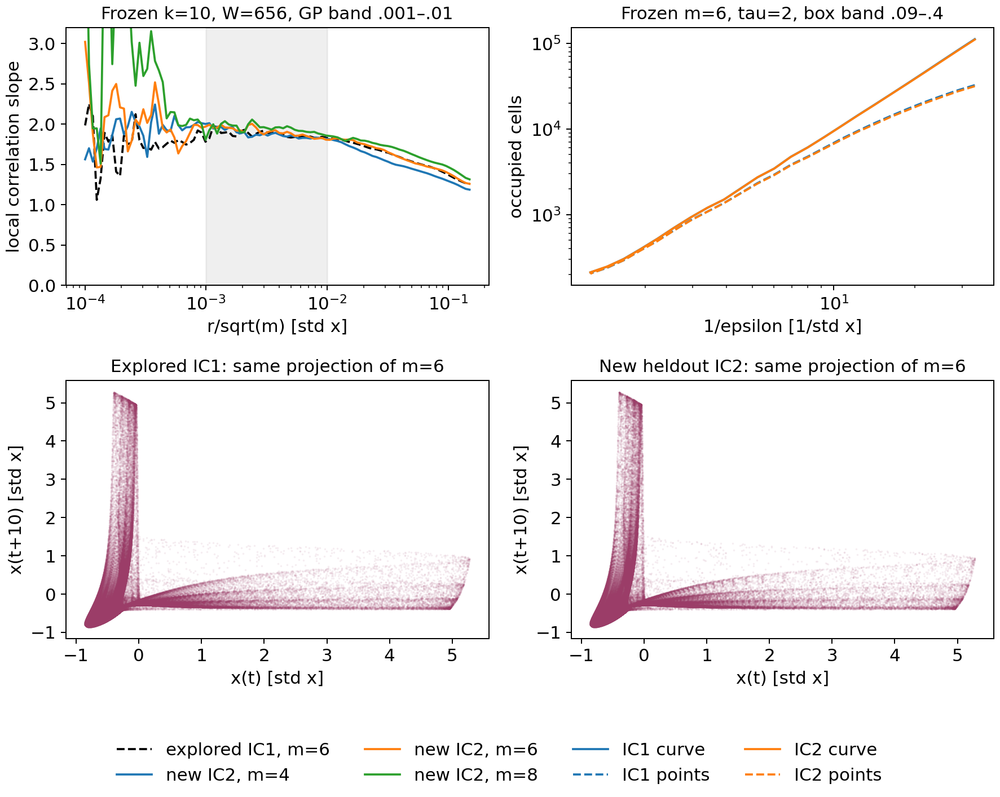

In [26]:
show_figure('figures/B_refined_heldout.png')

The selected m=6 result is consistent with the disclosed envelope. GP at m=8 and
some point-only box fits fall outside it. Thus the primary conclusion is supported,
but transferability of a narrow numerical interval is not proved.
Protocol: [heldout_frozen_settings.json](reproducibility/data/reconstruction_refinement/heldout_frozen_settings.json).
Both regular regimes agree across state returns, neutral model exponents and
curve geometry. Chaos is supported independently of reconstruction; scalar geometry
is consistent with it but does not establish an exact fractional dimension.
Every finite point file also has dimension zero at arbitrarily small scales; the
goal is resolved scaling of the underlying limit set, rather than that trivial file limit.
The steady limit set is one point, with D0=D2=0. Normalization by zero variance,
ACF and ordinary FNN are inapplicable to an established constant recording.

<a id="section-13"></a>

## C. Entropy-complexity analysis

<a id="section-14"></a>

### C1. Control signals

Three controls have the same N=150000 and dt=0.2: Gaussian white noise, a random
permutation of the chaotic HR record, and

$$s_{qp}(t)=\sin(2\pi t/T_0)+0.5\sin(2\pi\sqrt2\,t/T_0),\qquad T_0=20.127872376.$$

T0 is the full regular-spiking period. Shuffling preserves the exact amplitude
multiset and destroys temporal order. The quasiperiodic example has incommensurate
frequencies and is not classified as noise merely because it never repeats exactly.

In [27]:
controls = np.load(ROOT/'data/controls.npz')
assert np.array_equal(np.sort(controls['shuffled']), np.sort(x_clean))
assert all(len(controls[n])==len(x_clean) for n in ['white_noise','shuffled','quasiperiodic'])
print('Control lengths match; shuffling preserves the exact amplitude multiset.')

Control lengths match; shuffling preserves the exact amplitude multiset.


<a id="section-15"></a>

### C2. Ordinal probabilities, normalization and theoretical bounds

Bandt-Pompe patterns order $(u_i,u_{i+q},\ldots,u_{i+(\ell-1)q})$ by amplitude.
Window starts advance by one sample, and all K=ell! categories, including absent
ones, enter the distribution. Lehmer ranks encode permutations. Exact ties use
stable temporal-index order; no random jitter is added. Tie fractions are retained.
A constant record gives one convention-dependent pattern and is not interpreted
as an ordinal characterization of the equilibrium.

$$S(P)=-\sum_{p_j>0}p_j\ln p_j,\quad H=S(P)/\ln K,$$
$$J=S((P+P_e)/2)-S(P)/2-\ln K/2,$$
$$J_{max}(K)=\ln2+\tfrac12\ln K-\frac{K+1}{2K}\ln(K+1),\quad C=HJ/J_{max}.$$

J is maximal at a point mass, giving this normalization. Uniform and point-mass
limits are (H,C)=(1,0) and (0,0). The unit square is not the attainable region.
Every H-C comparison shows theoretical minimum and maximum curves for the full
alphabet K=ell!, with K=24 or 120:

$$P_{min}(p)=\left(p,\frac{1-p}{K-1},\ldots,\frac{1-p}{K-1}\right),\quad 1/K\le p\le1,$$
$$P_{max,n}(p)=\left(p,\underbrace{\frac{1-p}{n-1},\ldots,\frac{1-p}{n-1}}_{n-1},
\underbrace{0,\ldots,0}_{K-n}\right),\quad n=2,\ldots,K,\quad0\le p\le1/n.$$

Both families use the same full-K normalization as the observations, following
[Martin, Plastino and Rosso (2006)](https://doi.org/10.1016/j.physa.2005.11.053).
These are distributional bounds, not a noise/chaos decision boundary. The saved
curves are `data/complexity_bounds_K24.npz` and `data/complexity_bounds_K120.npz`.
Tests cover endpoints, support-size vertices, binary collapse, random distributions,
all 24 length-four permutations, ties, monotone sequences, increasing-transform
invariance and long IID controls. Independent tests also cover Jacobians, RK4,
events, GP pair exclusion, analytic-circle dimensions and cell traversal.

In [28]:
# ordpy computes the ordinal distribution and entropy/complexity from raw observations.
from library_validation import ordinal_library
rows=[]
for name in ['spiking','bursting','chaotic','white_noise','shuffled','quasiperiodic']:
    signal=(np.load(ROOT/f'data/{name}.npz')['state'][:-1,0]
            if name in ['spiking','bursting','chaotic'] else controls[name])
    out=ordinal_library(signal,5,10)
    rows.append({'signal':name,'H':out['H'],'C':out['C'],
                 'windows':out['patterns']})
ordinal = pd.DataFrame(rows)
expected=csv('entropy_complexity.csv')
np.testing.assert_allclose(ordinal[['H','C']],expected[['H','C']],rtol=0,atol=2e-12)
lo,hi=complexity_bounds(120)
assert all(np.isfinite(a).all() for a in [lo,hi])
display(ordinal)

,signal,H,C,windows
0,spiking,0.343953,0.277995,149960
1,bursting,0.353274,0.279879,149960
2,chaotic,0.394139,0.301186,149960
3,white_noise,0.999937,0.000113,149960
4,shuffled,0.999938,0.000111,149960
5,quasiperiodic,0.556953,0.381531,149960


<a id="section-16"></a>

### C3. Regimes, consecutive segments and current variation

Every primary signal uses ell=5,q=10,dt=0.2: element lag 2 and ordinal span 8.
No signal-specific tuning is used in this comparison.

| signal | H | C |
| --- | --- | --- |
| spiking | 0.343953 | 0.277995 |
| bursting | 0.353274 | 0.279879 |
| chaotic | 0.394139 | 0.301186 |
| white_noise | 0.999937 | 0.000113417 |
| shuffled | 0.999938 | 0.000111083 |
| quasiperiodic | 0.556953 | 0.381531 |

In [29]:
# Consecutive segments are descriptive, not independent noise replicates.
parts=[]
for j,part in enumerate(np.array_split(x_clean,6)):
    out=cnm.ordinal(part,5,10);parts.append({'segment':j,'H':out['H'],'C':out['C']})
display(pd.DataFrame(parts))
path=csv('entropy_transition.csv')
assert path.I.nunique() >= 15
print('Current values on the H-C path:', path.I.nunique())

,segment,H,C
0,0,0.392742,0.301280
1,1,0.393794,0.301013
2,2,0.395469,0.301442
3,3,0.392924,0.300383
4,4,0.394891,0.301582
5,5,0.394606,0.301386


Current values on the H-C path: 31


**C3: common settings and K=120 bounds; faint points are six consecutive segments**

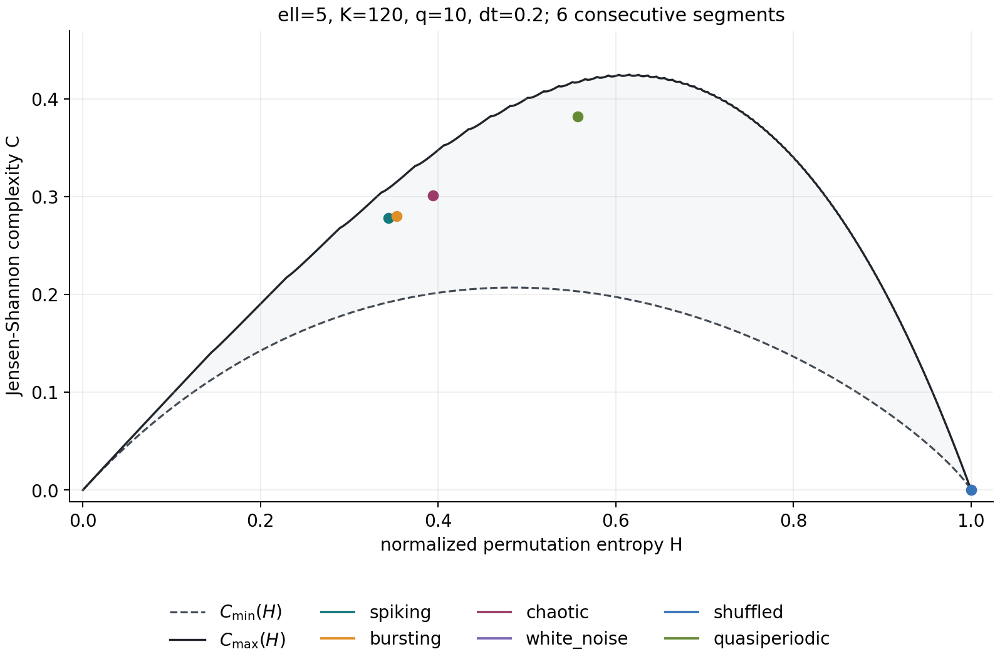

In [30]:
show_figure('figures/C_entropy_complexity.png')

| signal | H_mean | H_sd | H_min | H_max | C_mean | C_sd |
| --- | --- | --- | --- | --- | --- | --- |
| bursting | 0.353177 | 0.000784405 | 0.352274 | 0.354329 | 0.279823 | 0.000490236 |
| chaotic | 0.394071 | 0.00110219 | 0.392742 | 0.395469 | 0.301181 | 0.000434927 |
| quasiperiodic | 0.557017 | 0.000184693 | 0.556735 | 0.557249 | 0.381561 | 9.170e-05 |
| shuffled | 0.999561 | 0.000102107 | 0.999375 | 0.999659 | 0.000785147 | 0.000182788 |
| spiking | 0.343972 | 0.000142813 | 0.34372 | 0.344158 | 0.278008 | 7.796e-05 |
| white_noise | 0.999498 | 3.406e-05 | 0.999462 | 0.999545 | 0.000899175 | 6.265e-05 |

These standard deviations describe consecutive segments, rather than assuming
independence of overlapping ordinal windows. Noise and shuffle approach (1,0)
despite different amplitude distributions. Neuronal recordings retain structure.
Periodic bursting can have higher complexity than chaos at some delays; neither
H nor C is a universal indicator of a positive Lyapunov exponent.
For all 31 currents in the refined A3 region, H(I),C(I) and the ordered H-C path
are computed:

**C3: H(I), C(I) and a 31-current H-C path at ell=5,q=10**

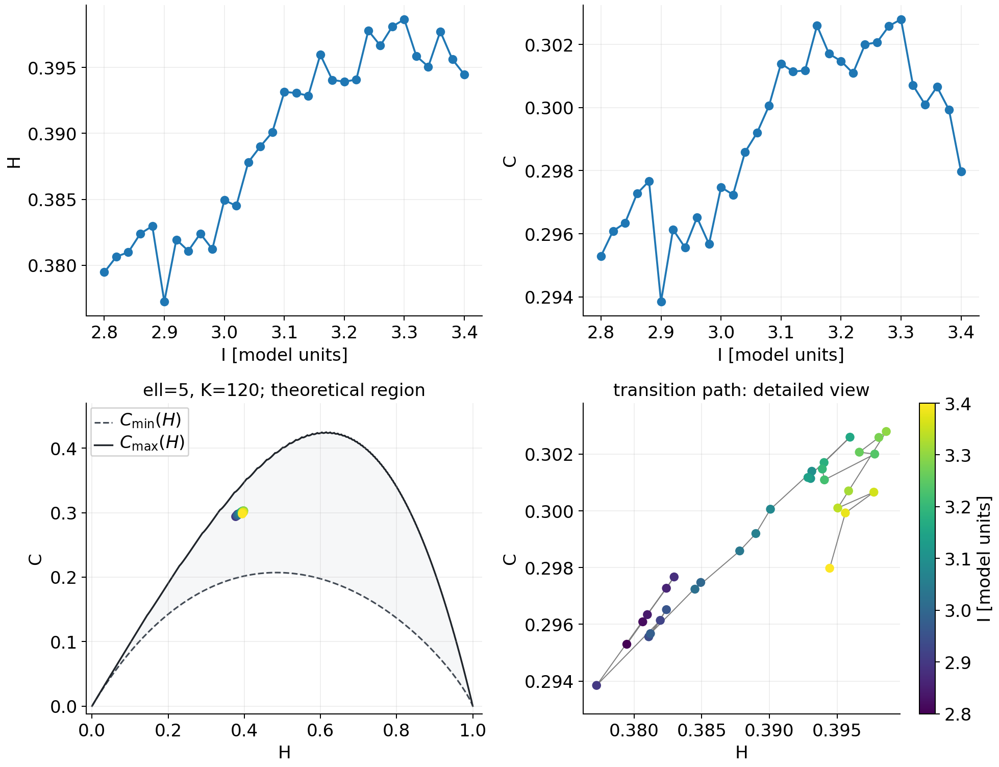

In [31]:
show_figure('figures/C_transition_path.png')

Periodic windows and nearby irregular regimes may project close together. H-C path
smoothness does not exclude a dynamical bifurcation; interpretation uses the maxima
and ISI diagrams as well. Data: [entropy_transition.csv](reproducibility/tables/entropy_transition.csv).

<a id="section-17"></a>

### C4. Analysis parameters and matched-scale sampling ablation

The broad study has 540 combinations: ell=4,5; q=1,5,10,25,50; observation steps
0.2,0.4,1; and 10%,50%,100% record lengths. Decimation reuses the saved trajectories
and noise arrays. The physical lag q*dt is retained explicitly.

In [32]:
ablation=csv('ablation_sampling_comparison.csv')
neuronal=ablation[(ablation.ell==5)&ablation.signal.isin(['spiking','bursting','chaotic'])]
display(pd.DataFrame([{
    'matched_physical_lag_max_H_drift':neuronal.fixed_physical_lag_H_minus_dt0p2.abs().max(),
    'fixed_q_max_H_drift':neuronal.fixed_q10_H_minus_dt0p2.abs().max()}]))
assert np.allclose(ablation.fixed_physical_lag_physical_element_lag,2.)
print('Both arms keep physical record duration fixed; their ordinal lags differ.')

,matched_physical_lag_max_H_drift,fixed_q_max_H_drift
0,0.00072,0.462466


Both arms keep physical record duration fixed; their ordinal lags differ.


**C4: ordinal delay and pattern-length sensitivity with the correct bounds**

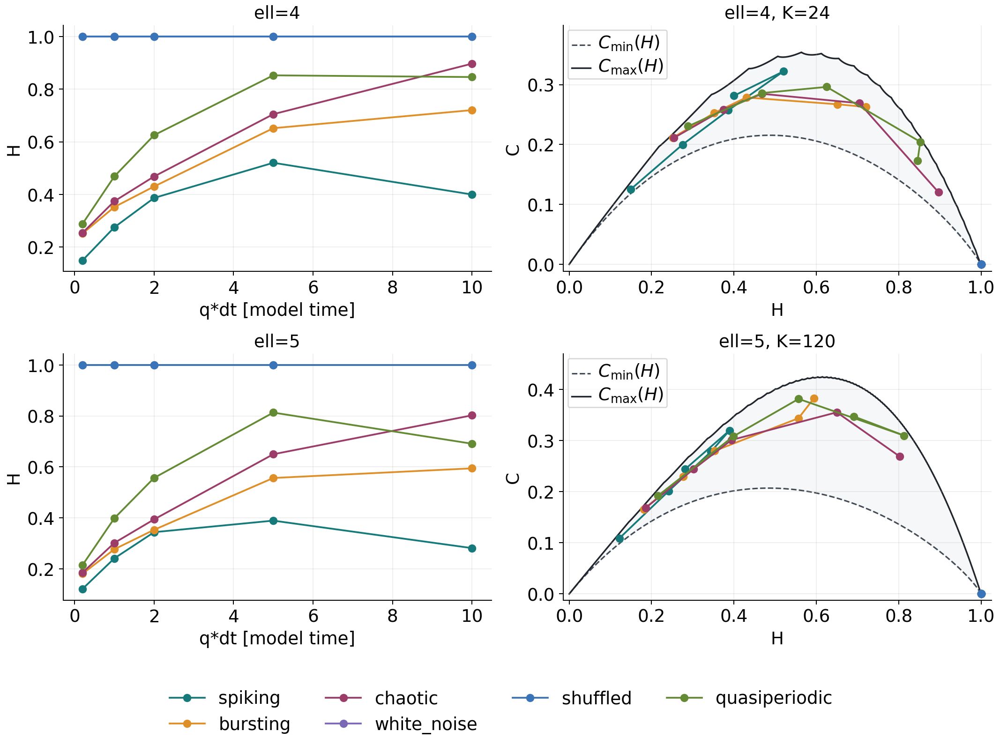

In [33]:
show_figure('figures/C_parameter_sensitivity.png')

| signal | patterns | occupied | patterns_per_possible | ties |
| --- | --- | --- | --- | --- |
| spiking | 149960 | 20 | 1249.67 | 0 |
| bursting | 149960 | 26 | 1249.67 | 0 |
| chaotic | 149960 | 29 | 1249.67 | 0 |
| white_noise | 149960 | 120 | 1249.67 | 0 |
| shuffled | 149960 | 120 | 1249.67 | 0 |
| quasiperiodic | 149960 | 30 | 1249.67 | 0 |

A primary 25000-sample segment has approximately 24960 windows, well above 120.
The shortest decimated cases have much smaller windows-per-category ratios,
recorded explicitly. Absent patterns in deterministic signals are not automatically
sampling errors. Overlap and dependence mean that N/K alone cannot prove accuracy.
All three neuronal pairs are compared using six segments: each cloud radius is
its maximum segment distance from its segment mean. A positive separation margin
means the descriptive circles do not intersect on these records, not a confidence
probability or a guarantee for a new source.

| ell | q | dt | first | second | distance_between_segment_means | sum_max_segment_radii | segment_discs_disjoint |
| --- | --- | --- | --- | --- | --- | --- | --- |
| 4 | 1 | 0.2 | spiking | bursting | 0.133409 | 0.00121976 | True |
| 4 | 1 | 0.2 | spiking | chaotic | 0.135204 | 0.000935148 | True |
| 4 | 1 | 0.2 | bursting | chaotic | 0.00257123 | 0.00111368 | True |
| 4 | 10 | 0.2 | spiking | bursting | 0.0484421 | 0.00167793 | True |
| 4 | 10 | 0.2 | spiking | chaotic | 0.086091 | 0.00202976 | True |
| 4 | 10 | 0.2 | bursting | chaotic | 0.0385829 | 0.00293878 | True |
| 5 | 10 | 0.2 | spiking | bursting | 0.00938192 | 0.00164363 | True |
| 5 | 10 | 0.2 | spiking | chaotic | 0.0551986 | 0.00170861 | True |
| 5 | 10 | 0.2 | bursting | chaotic | 0.0461357 | 0.00278026 | True |
| 5 | 50 | 0.2 | spiking | bursting | 0.342312 | 0.000553498 | True |
| 5 | 50 | 0.2 | spiking | chaotic | 0.518866 | 0.0271353 | True |
| 5 | 50 | 0.2 | bursting | chaotic | 0.232862 | 0.0273668 | True |

The largest short-to-full chaotic-record changes are:

| signal | ell | q | dt | HC_drift_short_to_full | short_N | short_patterns_per_possible |
| --- | --- | --- | --- | --- | --- | --- |
| chaotic | 5 | 25 | 1 | 0.0444563 | 3000 | 24.1667 |
| chaotic | 5 | 10 | 1 | 0.0422044 | 3000 | 24.6667 |
| chaotic | 5 | 50 | 1 | 0.0404188 | 3000 | 23.3333 |

The matched-scale ablation holds the physical interval [0,30000) fixed while using
dt=0.2,0.4,1,2 and q=10,5,2,1, preserving q*dt=2. Its control holds q=10 and
changes physical lag up to 20. Both arms save counts and six segments. Across the
three neuronal signals at ell=5, maximum absolute H drift is 0.000720 in the
matched arm versus 0.462466 in the fixed-q arm. Much of the broad sampling
sensitivity therefore reflects a changed time scale. Decimation still reduces
sample count and can create aliasing at coarser steps; this is not universal invariance.

**C4: matched physical delay versus the changing-delay control**

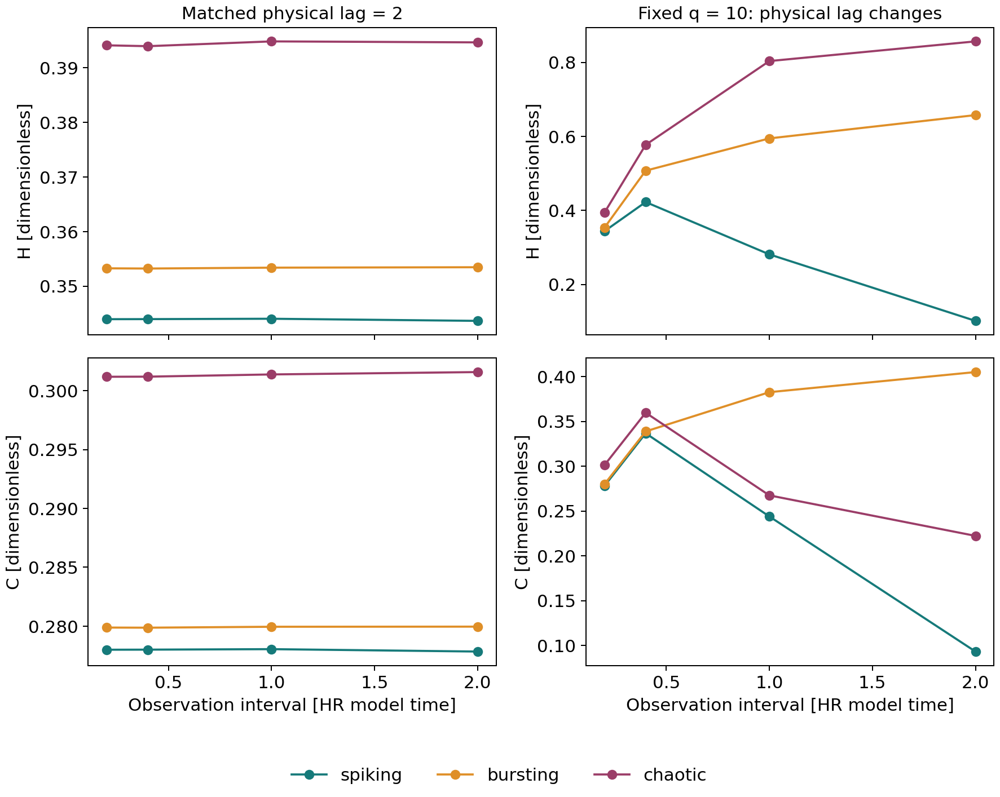

In [34]:
show_figure('figures/C_sampling_ablation.png')

Data: [entropy_sensitivity.csv](reproducibility/tables/entropy_sensitivity.csv),
[ablation_sampling_comparison.csv](reproducibility/tables/ablation_sampling_comparison.csv).

<a id="section-18"></a>

### C5. Measurement noise, paired Monte Carlo and noisy dimensions

After solving the ODEs, independent Gaussian measurement noise is added to regular
spiking and chaotic records: $u_n^{obs}=u_n+\eta\sigma_u\xi_n$,
eta=0,0.01,0.05,0.1,0.2. Each source's clean population-standard-deviation convention
(ddof=0) sets sigma. The original experiment uses five realizations at every nonzero
level and settings (ell,q)=(4,10),(5,10),(5,50). The clean level is not duplicated
as independent deterministic evidence.

In [35]:
# Reconstruct an actual observed record and recompute its ordinal metrics.
import noise_statistics as ns
meta=json.loads((ROOT/'data/noise_statistics_settings.json').read_text())
xi=np.load(ROOT/'data/noise_statistics_xi.npz')['xi']
regular=np.load(ROOT/'data/spiking.npz')['state'][:-1,0]
observed=ns.observed_signal(regular,xi[0],.05)
recount=cnm.ordinal(observed,5,10)
print('Recounted noisy regular record:',{'H':recount['H'],'C':recount['C']})
# Recompute a paired contrast and its bootstrap interval from all 30 draws.
values=np.load(ROOT/'data/noise_statistics_ordinal.npz')['values']
indices=np.load(ROOT/'data/noise_statistics_bootstrap.npz')['indices']
# Axes: replicate, source, eta, setting, metric. eta=.05; ell=5,q=10; metric H.
contrast=values[:,1,2,1,0]-values[:,0,2,1,0]
mc=ns.summarize_mc(contrast,indices)
reference=csv('noise_statistics_paired_contrasts.csv')
reference=reference[(reference.eta==.05)&(reference.ell==5)&(reference.q==10)&(reference.metric=='H')].iloc[0]
np.testing.assert_allclose([mc['mean'],mc['mcse'],mc['ci_low'],mc['ci_high']],
    [reference['mean'],reference.mcse,reference.ci_low,reference.ci_high],rtol=0,atol=2e-12)
display(pd.DataFrame([mc]))
display(csv('noise_statistics_distances.csv').query('ell == 5 and q == 10'))
print('Independent resampling units:',meta['replicates'],'complete replicate tuples')
zero=csv('noise_statistics_summary.csv').query('eta == 0')
assert (zero.mcse==0).all()

Recounted noisy regular record: {'H': 0.6196215145849869, 'C': 0.3133042012595187}


,n,mean,sd,mcse,ci_low,ci_high
0,30,0.17669,0.001143,0.000209,0.176281,0.177072


,eta,ell,q,dt,n,centroid_distance,centroid_mcse_delta_method,centroid_ci_low,centroid_ci_high,paired_distance_mean,paired_distance_sd,paired_distance_mcse,paired_distance_ci_low,paired_distance_ci_high
5,0.00,5,10,0.2,30,0.055285,0.000000,0.055285,0.055285,0.055285,0.000000,0.000000,0.055285,0.055285
6,0.01,5,10,0.2,30,0.148206,0.000162,0.147884,0.148520,0.148206,0.000890,0.000162,0.147885,0.148520
7,0.05,5,10,0.2,30,0.207849,0.000212,0.207444,0.208250,0.207850,0.001161,0.000212,0.207445,0.208250
8,0.10,5,10,0.2,30,0.175897,0.000208,0.175495,0.176307,0.175898,0.001137,0.000208,0.175495,0.176307
9,0.20,5,10,0.2,30,0.115362,0.000213,0.114962,0.115771,0.115363,0.001169,0.000213,0.114962,0.115771


Independent resampling units: 30 complete replicate tuples


**C5: original five-realization noise study; markers encode eta and bars show SD**

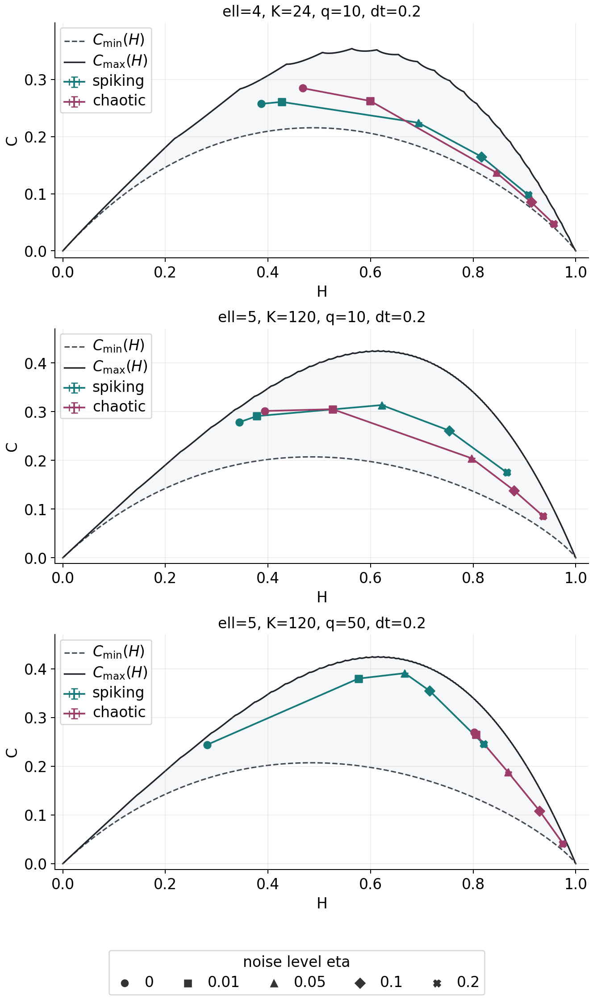

In [36]:
show_figure('figures/C_measurement_noise.png')

| signal | eta | ell | q | H_mean | H_sd | C_mean | C_sd | realizations |
| --- | --- | --- | --- | --- | --- | --- | --- | --- |
| chaotic | 0 | 5 | 10 | 0.394139 | not estimated | 0.301186 | not estimated | 1 |
| chaotic | 0.01 | 5 | 10 | 0.526014 | 0.000923217 | 0.304779 | 0.000345341 | 5 |
| chaotic | 0.05 | 5 | 10 | 0.797241 | 0.000369452 | 0.204061 | 0.000418764 | 5 |
| chaotic | 0.1 | 5 | 10 | 0.879682 | 0.000586898 | 0.138154 | 0.000596896 | 5 |
| chaotic | 0.2 | 5 | 10 | 0.936486 | 0.000309299 | 0.0853999 | 0.000394876 | 5 |
| spiking | 0 | 5 | 10 | 0.343953 | not estimated | 0.277995 | not estimated | 1 |
| spiking | 0.01 | 5 | 10 | 0.37827 | 0.00058473 | 0.290674 | 0.000186382 | 5 |
| spiking | 0.05 | 5 | 10 | 0.621485 | 0.000796239 | 0.313246 | 0.000501699 | 5 |
| spiking | 0.1 | 5 | 10 | 0.753466 | 0.000893377 | 0.260946 | 0.000564696 | 5 |
| spiking | 0.2 | 5 | 10 | 0.865236 | 0.00069543 | 0.175204 | 0.000763635 | 5 |

Small noise can reorder nearby amplitudes at short delays. At the same eta, the
two selected sources remain farther apart than the five-realization spread, but
distance changes nonmonotonically. Unknown noise magnitude still makes interpretation
of one H-C point ambiguous. Dominant IID noise drives both sources toward (1,0).
At q=50, physical lag 10 is near half the spiking period; it is particularly sensitive
to perturbations of almost repeated values, so larger q does not ensure robustness.

A separate supplement uses 30 independent Gaussian vectors of length 150000. Within
a replicate, the same vector is used for both sources, every eta and ordinal setting
(common random numbers). Replicates are independent. All vectors, their pre-draw
PCG64 states and ordinal counts are retained; observed arrays can be reconstructed
exactly. The original five realizations are preserved.
For one statistic per replicate, mean, sample SD and $MCSE=s_g/\sqrt{30}$ are reported.
A joint 10000-resample percentile bootstrap resamples complete replicate tuples,
using the same indices for contrasts. Intervals are pointwise approximate 95%
intervals conditional on these fixed clean trajectories. They exclude model,
between-neuron and new-clean-trajectory uncertainty and are not simultaneous bands.
At eta=0, Monte Carlo uncertainty is exactly zero.

The centroid distance $d_\eta=\|E(H,C)_{chaos}-E(H,C)_{regular}\|_2$ is recomputed
in each bootstrap sample. It is distinguished from mean within-pair distance,
which depends on the common-noise coupling. At ell=5,q=10:

| eta | centroid_distance | centroid_mcse_delta_method | centroid_ci_low | centroid_ci_high |
| --- | --- | --- | --- | --- |
| 0 | 0.055285 | 0 | 0.055285 | 0.055285 |
| 0.01 | 0.148206 | 0.000162437 | 0.147884 | 0.14852 |
| 0.05 | 0.207849 | 0.00021218 | 0.207444 | 0.20825 |
| 0.1 | 0.175897 | 0.000207584 | 0.175495 | 0.176307 |
| 0.2 | 0.115362 | 0.000213471 | 0.114962 | 0.115771 |

**C5: centroid-distance intervals and Monte Carlo mean convergence**

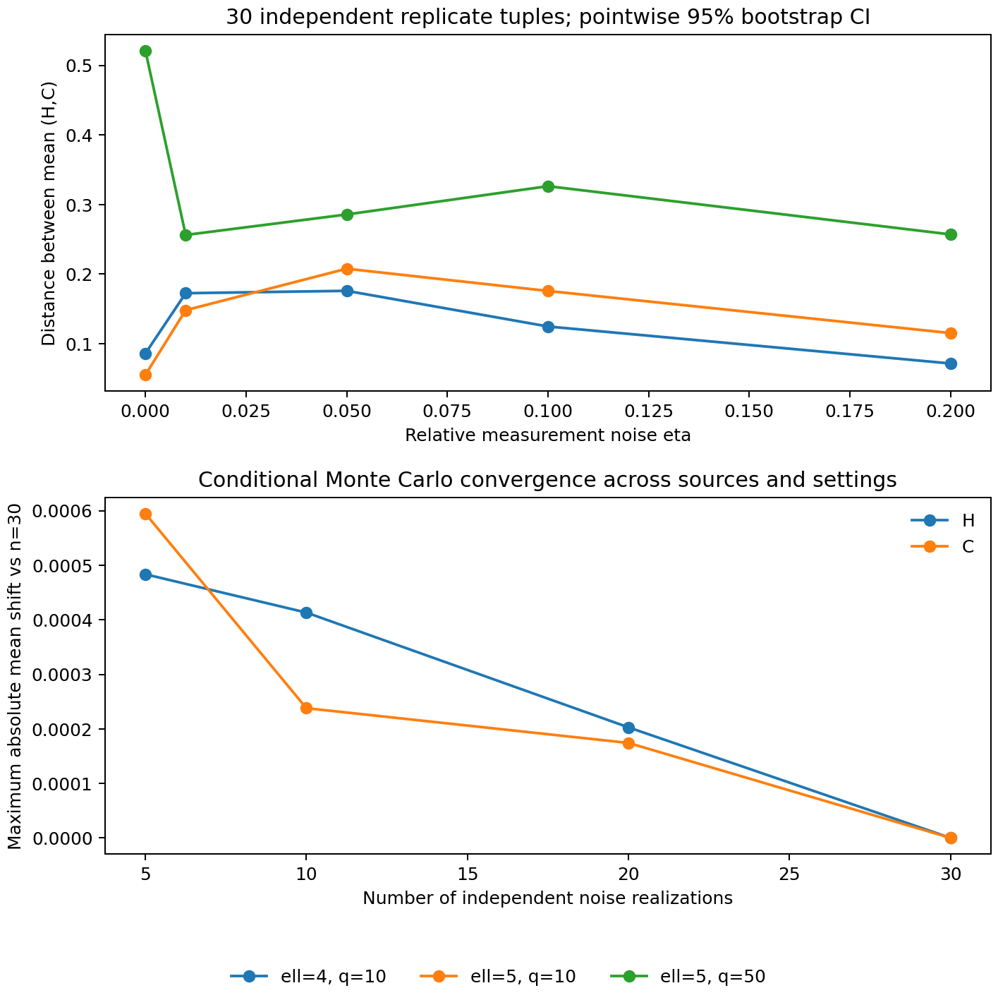

In [37]:
show_figure('figures/C_noise_statistics.png')

Intervals are narrower than plot markers; their numerical values are tabulated.
The nonmonotonic change is much larger than conditional Monte Carlo error. q=50
follows a different path. Paired MCSE includes source covariance; its ratio to the
naive unpaired estimate ranges from 0.791-1.021, so pairing need not reduce variance.
Maximum H,C mean shifts relative to n=30 are:

| n | maximum absolute mean shift vs n30 |
| --- | --- |
| 5 | 0.000594819 |
| 10 | 0.000413237 |
| 20 | 0.000202762 |
| 30 | 2.220e-16 |

These errors describe noise-ensemble means, not accuracy for classifying an individual
record. Full means, SD, MCSE and intervals:
[noise_statistics_summary.csv](reproducibility/tables/noise_statistics_summary.csv),
[noise_statistics_paired_contrasts.csv](reproducibility/tables/noise_statistics_paired_contrasts.csv).
For eta=0.05, realization 0 of the original regular-signal experiment, GP is repeated
at the same lag and W, m=2-6:

| eta | m | scale | estimate | local_min | local_max |
| --- | --- | --- | --- | --- | --- |
| 0.05 | 2 | clean_range | 1.80701 | 1.4472 | 1.96552 |
| 0.05 | 2 | alternative_range | 1.62741 | 1.35806 | 1.81804 |
| 0.05 | 3 | clean_range | 2.56319 | 1.82083 | 2.92506 |
| 0.05 | 3 | alternative_range | 2.18264 | 1.66013 | 2.58269 |
| 0.05 | 4 | clean_range | 3.30867 | 2.12756 | 3.86419 |
| 0.05 | 4 | alternative_range | 2.7038 | 1.87393 | 3.34316 |
| 0.05 | 5 | clean_range | 3.98171 | 2.31998 | 4.79291 |
| 0.05 | 5 | alternative_range | 3.11432 | 1.99287 | 4.0307 |
| 0.05 | 6 | clean_range | 4.69423 | 2.52009 | 5.83377 |
| 0.05 | 6 | alternative_range | 3.56047 | 2.11764 | 4.74438 |

**C5: noisy-cycle correlation sums and local slopes**

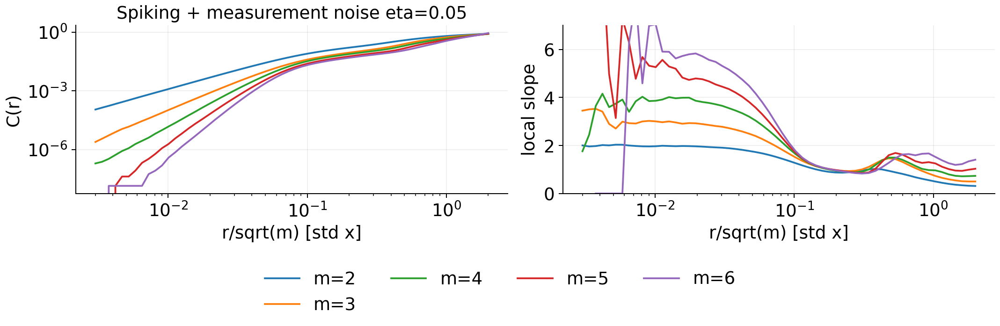

In [38]:
show_figure('figures/C_noisy_dimension.png')

Increasing small-scale slopes with m and loss of a common plateau do not mean the
source ODE became chaotic. Independent continuous measurement noise produces a
full-dimensional delay-space distribution at sufficiently small scales; intermediate
scales retain the curve's influence. A high dimension estimate alone cannot separate
noise from deterministic chaos.

<a id="section-19"></a>

## D. Overall synthesis and critical discussion

The summary uses ell=5,q=10,dt=0.2 and h=0.01 model exponents. Periodic finite-time
exponents are interpreted as consistent with zero. Dimension intervals are sensitivity
ranges, not confidence intervals. The chaotic row uses revised m=6,k=10; point and
polygonal capacity fits are distinguished. Regular D0 uses m=4 and four grid shifts.
The noisy row's H,C are means of the original five realizations. Not estimated
is distinct from zero, and not applicable is distinct from an unsuccessful estimate.

| origin | I | classification | lambda_max | k; m; W | D2 | D0 | H | C |
| --- | --- | --- | --- | --- | --- | --- | --- | --- |
| HR spiking | 4 | regular spiking | 3.438e-05 | 37; 3; 148 | 0.970-1.004: consistent with 1 | 1.017-1.050: finite-scale | 0.343953 | 0.277995 |
| HR bursting | 2.5 | periodic bursting | 4.880e-06 | 125; 5; 500 | 0.980-0.989: consistent with 1 | not estimated | 0.353274 | 0.279879 |
| HR chaotic | 3.25 | deterministic chaos: numerical evidence | 0.0135346 | 10; 6; 656 | 1.819-1.928: finite-scale; IC2 1.910 | 1.874-1.941: polyline, finite-scale; points 1.689-1.747 unreliable | 0.394139 | 0.301186 |
| HR steady | 1 | stable equilibrium | -0.012149 | not applicable | 0: theory | 0: theory | not applicable | not applicable |
| white_noise | not applicable | IID Gaussian | not applicable | not estimated | not estimated | not estimated | 0.999937 | 0.000113417 |
| shuffled | not applicable | random permutation of HR chaos | not applicable | not estimated | not estimated | not estimated | 0.999938 | 0.000111083 |
| quasiperiodic | not applicable | two incommensurate frequencies | not applicable | not estimated | not estimated | not estimated | 0.556953 | 0.381531 |
| HR spiking + measurement noise eta=.05 | 4 | periodic source + measurement noise | source model approximately 0 | 37; 2-6; 148 | no common plateau; see C5 | not estimated | 0.621485 | 0.313246 |

For these synthetic sources, the combined evidence distinguishes the selected
regular activity, deterministic chaos and a regularly generated signal with
measurement noise. A universal H-C threshold is not established.

1. Model equations provide direct evidence: an attracting equilibrium, full-state
   periodic return, or a consistently positive exponent on a bounded trajectory.
   Such evidence is unavailable for an arbitrary recording without a known model.
2. Reconstruction identifies curve geometry for regular signals and more complex
   chaotic geometry. Delay, coverage, temporal exclusion and resolved scales affect
   its estimates. Fractional limiting values are less secure than the curve/noncurve
   distinction. Independent held-out results expose residual m dependence.
3. Ordinal statistics efficiently reveal ordering destroyed by shuffling and separate
   the selected clean neuronal and IID examples. They depend on observation scale
   and are not in one-to-one correspondence with exponents or dimensions.
4. Measurement noise changes ordinal order and small-scale dimension, with nonmonotonic
   class-centroid distance. Multiple delays, controls and independent dynamical
   verification are necessary; narrow Monte Carlo intervals do not remove systematic bias.

The methods measure different objects: flow instability, measure/support geometry
at finite spatial scales, and ordering probabilities at a chosen temporal scale.
Discrepancies are therefore analyzed rather than hidden. Limits include finite
observation time, unresolved narrow parameter windows, restricted reconstruction
clouds, uncertain scaling limits, observation aliasing and a finite set of synthetic
sources. The study neither proves every bifurcation nor guarantees error-free
chaos detection in noisy experiments. Further classifier claims would require a
separate design and genuinely new source populations. In particular, this study
does not estimate a false-chaos probability on independent new recordings.
The 30 measurement-noise replicates condition on fixed clean trajectories; the
IC2 hold-out tests dimension choices, not classification sensitivity or specificity.
Thus, "distinguishable" refers to the selected examples and stated parameter settings.

In [39]:
display(csv('summary.csv'))
print('Intervals in the dimension columns are sensitivity ranges, not confidence intervals.')

,origin,I,classification,lambda_max,k; m; W,D2,D0,H,C
0,HR spiking,4.0,regular spiking,3.43840183968e-05,37; 3; 148,0.970-1.004: consistent with 1,1.017-1.050: finite-scale,0.34395282912,0.277994947407
1,HR bursting,2.5,periodic bursting,4.87951924801e-06,125; 5; 500,0.980-0.989: consistent with 1,not estimated,0.353273697638,0.279878575476
2,HR chaotic,3.25,deterministic chaos: numerical evidence,0.0135346229749,10; 6; 656,1.819-1.928: finite-scale; IC2 1.910,"1.874-1.941: polyline, finite-scale; points 1....",0.394138726883,0.301185728721
3,HR steady,1.0,stable equilibrium,-0.012148999707723278,not applicable,0: theory,0: theory,not applicable,not applicable
4,white_noise,not applicable,IID Gaussian,not applicable,not estimated,not estimated,not estimated,0.999936598464,0.000113416878721
5,shuffled,not applicable,random permutation of HR chaos,not applicable,not estimated,not estimated,not estimated,0.999937880387,0.000111083065079
6,quasiperiodic,not applicable,two incommensurate frequencies,not applicable,not estimated,not estimated,not estimated,0.556952509238,0.381531281316
7,HR spiking + measurement noise eta=.05,4.0,periodic source + measurement noise,source model approximately 0,37; 2-6; 148,no common plateau; see C5,not estimated,0.6214846164360001,0.3132456733316


Intervals in the dimension columns are sensitivity ranges, not confidence intervals.


<a id="section-20"></a>

## References

Reconstruction, FNN, temporal exclusion and dimension diagnostics follow the
primary methodological sources below.
The assignment has numbered citations without a bibliography; the actual primary
sources used here are listed explicitly rather than assigning invented numbers.

- Hindmarsh and Rose (1984), [A model of neuronal bursting using three coupled first order differential equations](https://doi.org/10.1098/rspb.1984.0024).
- Grassberger and Procaccia (1983), [Characterization of Strange Attractors](https://doi.org/10.1103/PhysRevLett.50.346).
- Theiler (1986), [Spurious dimension from correlation algorithms applied to limited time-series data](https://doi.org/10.1103/PhysRevA.34.2427).
- Kennel, Brown and Abarbanel (1992), [Determining embedding dimension for phase-space reconstruction using a geometrical construction](https://doi.org/10.1103/PhysRevA.45.3403).
- Fraser and Swinney (1986), [Independent coordinates for strange attractors from mutual information](https://doi.org/10.1103/PhysRevA.33.1134).
- Bandt and Pompe (2002), [Permutation Entropy: A Natural Complexity Measure for Time Series](https://doi.org/10.1103/PhysRevLett.88.174102).
- Rosso et al. (2007), [Distinguishing Noise from Chaos](https://doi.org/10.1103/PhysRevLett.99.154102).

---

# Section 5. Hodgkin-Huxley and Izhikevich comparison

The supplementary question is which activity characteristics survive replacement
of a conductance-based HH reference by a fixed two-variable Izhikevich model.
The models use the prescribed parameters and initial states. A single positive
affine input mapping is calibrated on designated DC currents, then frozen for
all subsequent comparisons. The evidence concerns individual synthetic neurons
in the investigated input range; network behavior and biological validity are
outside the experiment. The calibration ablation uses its own HH/Izhikevich
records, not HR observations.

<a id="section-21"></a>

## 5.1. HH reference and numerical method

All four variables $(V,m_g,h_g,n_g)$ are integrated and retained:

$$\dot V=J(t)-120m_g^3h_g(V-50)-36n_g^4(V+77)-0.3(V+54.387),$$
$$\dot q_g=\alpha_q(V)(1-q_g)-\beta_q(V)q_g.$$

Capacitance is 1 microfarad/cm squared; conductances are 120,36,0.3 mS/cm squared;
reversal potentials are 50,-77,-54.387 mV. Time is in ms, voltage in mV and J
in microampere/cm squared. No temperature factor is introduced. The exact rates are

$$\alpha_m=0.1\phi(V+40),\quad\beta_m=4e^{-(V+65)/18},$$
$$\alpha_h=0.07e^{-(V+65)/20},\quad\beta_h=(1+e^{-(V+35)/10})^{-1},$$
$$\alpha_n=0.01\phi(V+55),\quad\beta_n=0.125e^{-(V+65)/80},\quad
\phi(z)=\frac{z}{-\operatorname{expm1}(-z/10)}.$$

Near zero, $\phi(z)=10+z/2+z^2/120-z^4/720000$, giving the finite limits
alpha_m(-40)=1 and alpha_n(-55)=0.1. Initial V=-65 and gates are the prescribed
stationary fractions alpha/(alpha+beta); exact values are saved in
[settings.json](reproducibility/optional/settings.json). HH spikes are positive crossings of V=0.

Both models use classical RK4 with h=0.01 ms. Spike times are localized with
24 bisections of a partial RK4 step. Uniform observations use dt=0.2 ms.
Selected convergence checks repeat the entire transient from the initial state
at h=0.005, then compare the first 400 observed ms:

| signal | coarse_h_ms | fine_h_ms | max_spike_difference_ms | coarse_spikes | fine_spikes | voltage_RMS_mV |
| --- | --- | --- | --- | --- | --- | --- |
| HH_DC | 0.01 | 0.005 | 4.1755e-06 | 27 | 27 | 0.00012883 |
| Izh_DC | 0.01 | 0.005 | 2.1905e-08 | 21 | 21 | 5.1932e-07 |
| HH_weak | 0.01 | 0.005 | 6.9024e-06 | 27 | 27 | 0.00012683 |
| Izh_weak | 0.01 | 0.005 | 4.6196e-09 | 20 | 20 | 3.5462e-08 |
| HH_strong | 0.01 | 0.005 | 2.7567e-08 | 20 | 20 | 5.4189e-06 |
| Izh_strong | 0.01 | 0.005 | 0.00015884 | 35 | 35 | 0.001136 |

Maximum event-time difference is 0.000159 ms. Event and trajectory
checks support the chosen numerical precision; they do not convert a finite-time
threshold bracket into an asymptotically exact bifurcation value.

In [40]:
import models
for voltage in [-40., -55.]:
    gates=models.rates(voltage)
    assert np.isfinite(gates).all()
    print('HH finite rates at V =',voltage,':',gates)
from forced_lyapunov import analytic_jacobian
assert np.isfinite(analytic_jacobian(0,models.initial(0))).all()

HH finite rates at V = -40.0 : [1.         0.99740884 0.02005534 0.37754067 0.19308254 0.09145195]
HH finite rates at V = -55.0 : [0.43082538 2.29501368 0.04245715 0.11920292 0.1        0.11031211]


<a id="section-22"></a>

## 5.2. Fixed Izhikevich model and hybrid events

$$\dot v=0.04v^2+5v+140-u+I_{Izh}(t),\qquad\dot u=0.02(0.2v-u).$$

At v=30 mV, $R(v,u)=(-65,u+8)$; the initial state is (-65,-13).
The parameters a=0.02,b=0.2,c=-65,d=8 are never fitted. Voltage follows the
assignment's mV scale; recovery and input use model units, and time is in ms.
Input scales are therefore matched explicitly instead of assumed identical.
The event time is located first, the state is moved to the event surface, reset
is applied, and the remaining fraction of the same internal step is integrated.
Reset is not delayed to the next output sample. Observations are right-continuous
at the jump. Izh spikes are reset events; the different HH event convention
affects phase but not a stationary firing rate and is retained explicitly.

<a id="section-23"></a>

## 5.3.1. Calibration and held-out validation

$$I_{HH}=J,\qquad I_{Izh}=\kappa J+\beta,\qquad\kappa>0.$$

The objective is unweighted squared frequency error in Hz at training currents
J=0,5,8,10,15,20. The rate estimator is $1000/\overline{ISI}$ with at least
three observed spikes, otherwise zero, after a 1000-ms transient and over 2000 ms.
A positive parameterization kappa=exp(theta) enforces the constraint. An Izh DC
lookup with step 0.25 and h=0.02 initializes the search; actual h=0.01 integrations
refine a Nelder-Mead solution. Validation currents J=7,9,12,18 affect neither
initialization nor fitting. The fitted values are kappa=2.146108 model-input units
per microampere/cm squared and beta=2.232621 model-input units. Full precision is
saved in [calibration.json](reproducibility/optional/calibration.json) and remains fixed afterwards.

| split | J_uA_cm2 | I_Izh_model_units | HH_Hz | Izh_Hz | error_Hz |
| --- | --- | --- | --- | --- | --- |
| train | 0 | 2.2326 | 0 | 0 | 0 |
| train | 5 | 12.963 | 0 | 28.67 | 28.67 |
| train | 8 | 19.401 | 62.47 | 42.358 | -20.112 |
| train | 10 | 23.694 | 68.324 | 51.513 | -16.811 |
| train | 15 | 34.424 | 78.649 | 74.657 | -3.9923 |
| train | 20 | 45.155 | 86.47 | 98.297 | 11.827 |
| validation | 7 | 17.255 | 58.327 | 37.795 | -20.532 |
| validation | 9 | 21.548 | 65.629 | 46.93 | -18.699 |
| validation | 12 | 27.986 | 72.919 | 60.72 | -12.2 |
| validation | 18 | 40.863 | 83.535 | 88.777 | 5.2428 |

| split | RMSE_Hz | MAE_Hz | max_abs_Hz |
| --- | --- | --- | --- |
| train | 16.658 | 13.569 | 28.67 |
| validation | 15.391 | 14.168 | 20.532 |

In [41]:
# Recompute train/validation errors; no parameter refitting here.
cal=csv('calibration.csv',optional=True)
errors=cal.groupby('split').error_Hz.agg(
    RMSE_Hz=lambda v:np.sqrt(np.mean(v**2)),MAE_Hz=lambda v:np.mean(abs(v)))
display(errors)
display(csv('ablation_calibration_scores.csv').query("arm in ['identity','frozen_fitted']"))
assert set(cal.loc[cal.split=='train','J_uA_cm2'])=={0,5,8,10,15,20}
assert set(cal.loc[cal.split=='validation','J_uA_cm2'])=={7,9,12,18}

,RMSE_Hz,MAE_Hz
split,,
train,16.657617,13.568575
validation,15.390919,14.168268


,split,arm,currents,h_ms,transient_ms,duration_ms,RMSE_Hz,MAE_Hz,max_abs_Hz,SSE_Hz2,parameters_refitted
0,train,identity,6,0.02,1000.0,2000.0,36.817753,31.615479,46.008453,8133.281594,False
1,train,frozen_fitted,6,0.02,1000.0,2000.0,16.657617,13.568575,28.669967,1664.857178,False
3,validation,identity,4,0.02,1000.0,2000.0,44.678558,44.657326,46.304809,7984.694064,False
4,validation,frozen_fitted,4,0.02,1000.0,2000.0,15.390919,14.168268,20.531981,947.521564,False


**DC calibration; filled training and open validation markers**

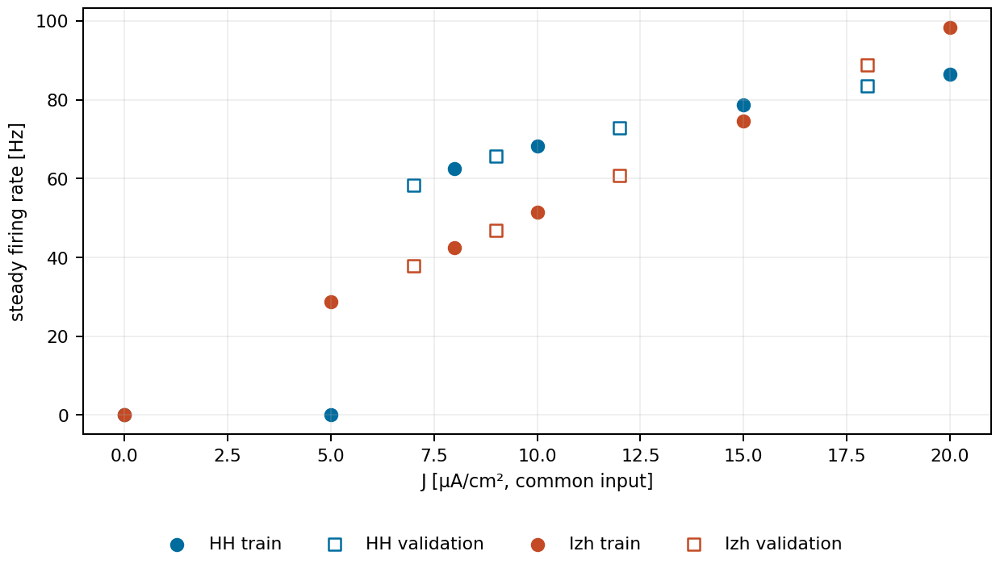

In [42]:
show_figure('optional/figures/calibration.png')

### Ablation of the input transformation

The identity mapping kappa=1,beta=0 and the frozen fitted mapping are compared
with the same Izh equations, initial state, 1000-ms transient, 2000-ms observation
and h=0.02. Both branches are newly integrated; no optimization or validation
retuning occurs. The rate estimator is unchanged.

| split | arm | RMSE_Hz | MAE_Hz | max_abs_Hz |
| --- | --- | --- | --- | --- |
| train | identity | 36.818 | 31.615 | 46.008 |
| train | frozen_fitted | 16.658 | 13.569 | 28.67 |
| validation | identity | 44.679 | 44.657 | 46.305 |
| validation | frozen_fitted | 15.391 | 14.168 | 20.532 |

**Effect of frozen input calibration on train and validation errors**

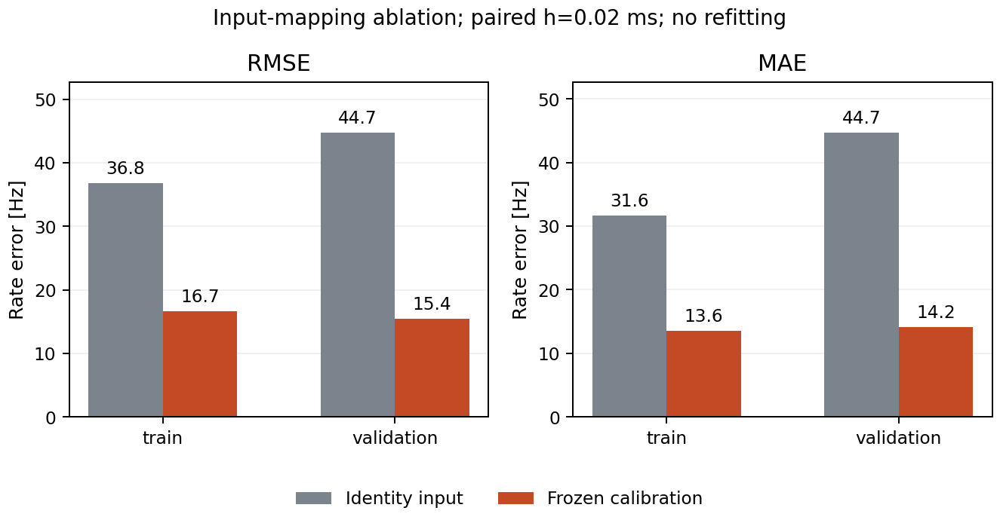

In [43]:
show_figure('optional/figures/calibration_ablation.png')

Calibration reduces both errors but leaves substantial mismatch. The frozen h=0.02
rates differ from the original h=0.01 fitted rates by at most 4.44e-08
Hz, excluding step size as the explanation of the improvement.
[Paired rates](reproducibility/tables/ablation_calibration_rates.csv) and
[error scores](reproducibility/tables/ablation_calibration_scores.csv) retain every current.
This ablates input matching, not a prescribed neuron mechanism.

Five independent differential-evolution starts on the training lookup and
alternative constraints on active training points probe optimization sensitivity:

| method | kappa | beta | lookup_SSE_Hz2 | exact_SSE_Hz2 |
| --- | --- | --- | --- | --- |
| independent_DE_seed_1 | 2.1463 | 2.23 | 1664.9 | — |
| independent_DE_seed_2 | 2.1463 | 2.23 | 1664.9 | — |
| independent_DE_seed_3 | 2.1463 | 2.2299 | 1664.9 | — |
| independent_DE_seed_4 | 2.1463 | 2.2299 | 1664.9 | — |
| independent_DE_seed_5 | 2.1463 | 2.2298 | 1664.9 | — |
| J0_active_refined | 2.0356 | 3.81 | 1677.6 | 1707.9 |
| J5_quiet_refined | 2.9782 | -11.141 | 2344.8 | 2344.8 |
| selected_exact_train_fit | 2.1461 | 2.2326 | 1664.9 | 1664.9 |

The tested starts agree near the same minimum. Requiring silence at J=5 increases
training SSE. This exposes a calibration tradeoff, without proving global
optimality on an unbounded parameter domain or impossibility for every other
criterion. The fitted model can fire where HH remains quiet; onset mismatch is
quantified separately.

### Operational thresholds and transient false positives

Sustained firing is defined on the finite observation interval: every one of four
equal windows must contain at least three spikes, window mean-ISI rates must vary
by at most 1%, and the final silent gap must not exceed twice the median of the
last eight ISIs. The rule is saved in `data/firing_criterion.json`.
The basic threshold search uses transient 1500 ms, observation 3000 ms and
bisection at h=0.02,0.01,0.005:

| model | h_ms | J_lower_uA_cm2 | J_upper_uA_cm2 | threshold_mid | bracket_width_uA_cm2 | transient_ms | duration_ms |
| --- | --- | --- | --- | --- | --- | --- | --- |
| HH | 0.02 | 6.2603 | 6.2603 | 6.2603 | 1.1444e-05 | 1500 | 3000 |
| HH | 0.01 | 6.2603 | 6.2603 | 6.2603 | 1.1444e-05 | 1500 | 3000 |
| Izh | 0.02 | 0.71838 | 0.7184 | 0.71839 | 1.9073e-05 | 1500 | 3000 |
| Izh | 0.01 | 0.71838 | 0.7184 | 0.71839 | 1.9073e-05 | 1500 | 3000 |

A total count of at least three spikes is insufficient: the recorded regression
case fires 15 times near the beginning and then stays silent. Window and tail
checks reject it:

| model | old_definition | J_uA_cm2 | transient_ms | duration_ms | data_file | old_total_count_passed | sustained | total_events | window_count_min | window_rate_relative_range | tail_median_ISI_ms | last_gap_ms | last_event_ms | last_gap_in_tail_ISI |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| HH | short | 6.2602 | 1500 | 3000 | data/old_threshold_false_positive_HH_short.npz | True | False | 7 | 0 | — | 20.169 | 2867.3 | 132.69 | 142.17 |
| HH | long | 6.2603 | 3000 | 6000 | data/old_threshold_false_positive_HH_long.npz | True | False | 15 | 0 | — | 20.118 | 5715.6 | 284.35 | 284.1 |

Independent definitions compare first-spike onset over 200 ms without transient
with sustained firing after transient 3000 and observation 6000:

| model | definition | J_lower_uA_cm2 | J_upper_uA_cm2 | duration_ms |
| --- | --- | --- | --- | --- |
| HH | first_spike | 2.2368 | 2.2368 | 200 |
| HH | sustained_long | 6.2603 | 6.2603 | 6000 |
| Izh | first_spike | 0.56751 | 0.56752 | 200 |
| Izh | sustained_long | 0.71838 | 0.7184 | 6000 |

| model | short_mid | doubled_mid | finite_time_shift_uA_cm2 |
| --- | --- | --- | --- |
| HH | 6.2603 | 6.2603 | 0 |
| Izh | 0.71839 | 0.71839 | -2.3842e-06 |

These are operational finite-time thresholds. Bracket width measures localization
of the chosen criterion, not uncertainty in an infinite-time bifurcation.
Near onset HH has a large finite firing-rate gap, whereas Izh has a much smaller
one. Count rates at the upper long-observation endpoints are:

| model | J_upper_uA_cm2 | upper_events | duration_ms | count_rate_Hz |
| --- | --- | --- | --- | --- |
| HH | 6.2603 | 301 | 6000 | 50.167 |
| Izh | 0.7184 | 26 | 6000 | 4.3333 |

Thus the comparison uses quantitative onset behavior instead of claiming that
one f-I curve is necessarily mathematically continuous. The input calibration
is unchanged after correcting the sustained-firing test. Independent tail checks
find 17 active and 3 quiet responses among all 20 saved
calibration/validation records; the active windows contain at least 14
events. The original frequency fit is not contaminated by the transient-count
false positive. Data and boundary trajectories:
[calibration_tail_stability.csv](reproducibility/optional/tables/calibration_tail_stability.csv),
[threshold_definition_checks.csv](reproducibility/optional/tables/threshold_definition_checks.csv).

<a id="section-24"></a>

## 5.3.2. Periodic forcing, synchronization and transitions

$$J(t)=10+A\sin(2\pi t/T),\quad T\in\{10,20,40\}\;\mathrm{ms},\quad A\in[0,15].$$

A is in microampere/cm squared. The amplitude grid is 0.5 for T=10,40 and 0.1
for the detailed T=20 study (151 values). Every point restarts from the prescribed
initial state, discards 100 forcing cycles and observes 200. All state components,
uniform dt=0.2 records, spike times and fixed-phase stroboscopic states X(nT) are
saved. The experiment does not exclude additional coexisting attractors.
Synchronization uses spikes per input cycle, ISI, full-state stroboscopic recurrence
and phase resultants $R_k=|\langle e^{ik2\pi t_{spike}/T}\rangle|$, k=1,2.
R1 below 1 alone does not exclude multispike locking.
A period p<=8 is accepted when the scaled late-state recurrence RMS is below 1e-5;
state scales are (100,1,1,1) for HH and (100,30) for Izh. Label zero means that
period <=8 is unresolved, not that chaos is proved.

In [44]:
# Validate a refined hybrid map using its actual state and frozen calibration.
from forced_lyapunov import period_map
orbit=np.load(ROOT/'optional/data/orbit_Izh.npz')
mapping=json.loads((ROOT/'optional/calibration.json').read_text())
T=float(orbit['T_ms']); A=float(orbit['A_uA_cm2'])
end,M,events=period_map(1,orbit['phase0_state'],T,
    (10.,A,T,mapping['kappa'],mapping['beta']),h=.005)
assert np.max(np.abs(end-orbit['phase0_state'])) < 1e-5
np.testing.assert_allclose(M,orbit['monodromy'],rtol=2e-5,atol=1e-6)
print('Recomputed hybrid closure residual:',np.max(np.abs(end-orbit['phase0_state'])))
print('Recomputed Floquet multipliers:',np.linalg.eigvals(M))
display(csv('periodic_orbits.csv',optional=True))
forced=csv('forced_lyapunov.csv',optional=True)
last=forced[(forced.signal=='Izh_strong')&(forced.observation_ms==32000)]
assert (last.quarter_min_per_ms>0).all()
display(last[['signal','h_ms','lambda_max_per_ms','quarter_min_per_ms','quarter_max_per_ms']])
print('Positive exponent is independent of the entropy-complexity calculation.')

Recomputed hybrid closure residual: 4.972378064849181e-11
Recomputed Floquet multipliers: [-8.88178420e-15  7.03749021e-01]


,model,T_ms,A_uA_cm2,root_success,residual_max,spectral_radius,multipliers,FD_relative_error,tight_tolerance_matrix_difference,wrong_DR_only_spectral_radius,events_per_period
0,HH,20.0,10.1,True,1.080025e-12,0.025365,[-1.15670012e-02 2.53654208e-02 4.28436153e-...,2.826729e-06,1.672671e-10,NaN,NaN
1,Izh,20.0,13.8,True,1.421085e-14,0.703749,[-8.99280650e-15 7.03749021e-01],4.391555e-10,1.083679e-11,0.581604,2.0


,signal,h_ms,lambda_max_per_ms,quarter_min_per_ms,quarter_max_per_ms
15,Izh_strong,0.020,0.00140,0.000901,0.001807
19,Izh_strong,0.010,0.00191,0.001378,0.002796
23,Izh_strong,0.005,0.00187,0.001484,0.002200


Positive exponent is independent of the entropy-complexity calculation.


**Responses at all three forcing periods**

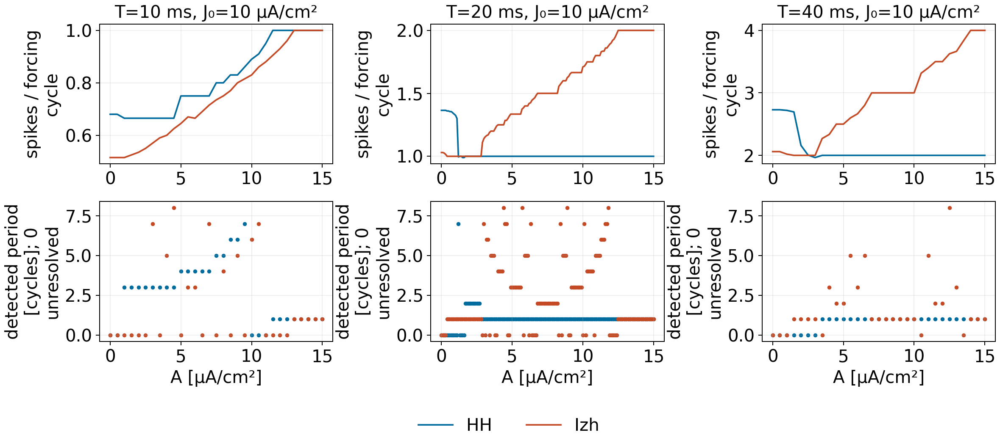

In [45]:
show_figure('optional/figures/forcing_overview.png')

**Detailed amplitude sweep at T=20 ms**

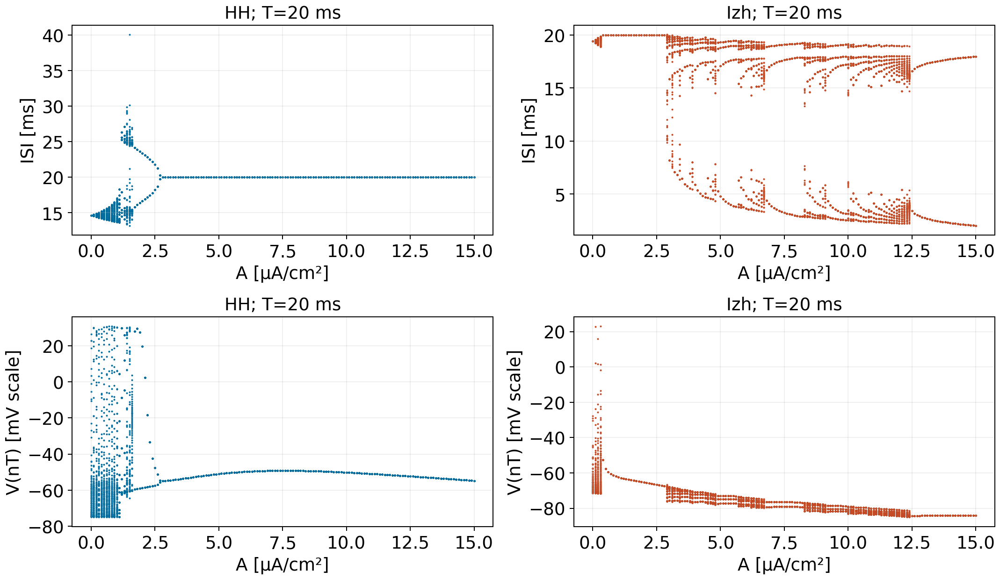

In [46]:
show_figure('optional/figures/detailed_T20.png')

Grid-contiguous stroboscopic-period intervals at T=20:

| model | A_min | A_max | period_cycles | mean_spikes_per_cycle | grid_points |
| --- | --- | --- | --- | --- | --- |
| HH | 0 | 1.1 | 0 | 1.3496 | 12 |
| HH | 1.2 | 1.2 | 7 | 0.995 | 1 |
| HH | 1.3 | 1.6 | 0 | 0.995 | 4 |
| HH | 1.7 | 2.7 | 2 | 1 | 11 |
| HH | 2.8 | 15 | 1 | 1 | 123 |
| Izh | 0 | 0.3 | 0 | 1.025 | 4 |
| Izh | 0.4 | 2.8 | 1 | 1 | 25 |
| Izh | 2.9 | 2.9 | 0 | 1.11 | 1 |
| Izh | 3 | 3 | 7 | 1.14 | 1 |
| Izh | 3.1 | 3.1 | 0 | 1.155 | 1 |
| Izh | 3.2 | 3.3 | 6 | 1.1675 | 2 |
| Izh | 3.4 | 3.4 | 0 | 1.19 | 1 |
| Izh | 3.5 | 3.7 | 5 | 1.2 | 3 |
| Izh | 3.8 | 3.9 | 0 | 1.23 | 2 |
| Izh | 4 | 4.3 | 4 | 1.25 | 4 |
| Izh | 4.4 | 4.4 | 8 | 1.25 | 1 |
| Izh | 4.5 | 4.6 | 7 | 1.285 | 2 |
| Izh | 4.7 | 4.8 | 0 | 1.31 | 2 |
| Izh | 4.9 | 5.6 | 3 | 1.335 | 8 |
| Izh | 5.7 | 5.7 | 8 | 1.375 | 1 |
| Izh | 5.8 | 5.8 | 0 | 1.385 | 1 |
| Izh | 5.9 | 6.1 | 5 | 1.4 | 3 |
| Izh | 6.2 | 6.2 | 0 | 1.42 | 1 |
| Izh | 6.3 | 6.3 | 7 | 1.425 | 1 |
| Izh | 6.4 | 6.7 | 0 | 1.4625 | 4 |
| Izh | 6.8 | 8.2 | 2 | 1.5 | 15 |
| Izh | 8.3 | 8.3 | 0 | 1.555 | 1 |
| Izh | 8.4 | 8.4 | 7 | 1.57 | 1 |
| Izh | 8.5 | 8.5 | 0 | 1.585 | 1 |
| Izh | 8.6 | 8.8 | 5 | 1.6 | 3 |
| Izh | 8.9 | 8.9 | 8 | 1.625 | 1 |
| Izh | 9 | 9.1 | 0 | 1.645 | 2 |
| Izh | 9.2 | 9.9 | 3 | 1.665 | 8 |
| Izh | 10 | 10 | 0 | 1.71 | 1 |
| Izh | 10.1 | 10.1 | 7 | 1.715 | 1 |
| Izh | 10.2 | 10.2 | 0 | 1.73 | 1 |
| Izh | 10.3 | 10.7 | 4 | 1.75 | 5 |
| Izh | 10.8 | 10.8 | 0 | 1.78 | 1 |
| Izh | 10.9 | 11.2 | 5 | 1.8 | 4 |
| Izh | 11.3 | 11.5 | 6 | 1.8333 | 3 |
| Izh | 11.6 | 11.7 | 7 | 1.86 | 2 |
| Izh | 11.8 | 11.8 | 8 | 1.875 | 1 |
| Izh | 11.9 | 12.4 | 0 | 1.9275 | 6 |
| Izh | 12.5 | 15 | 1 | 2 | 26 |

These boundaries initially have amplitude-grid resolution 0.1. An apparent
period multiple alone does not identify a bifurcation type. Unresolved responses
could be quasiperiodic, long-transient, long-period or chaotic.
Convergence checks around short p7/p8 islands and locking boundaries cover
22 amplitudes, transient 16000 ms, observation 4000 ms, and h=0.01,0.005.
The recurrence label matches the primary grid in 44/44 checks.
Maximum spikes-per-cycle difference is 0.015; finite-time ratios are
not declared exact asymptotic rotation numbers.
Two boundaries are also examined with amplitude step 0.01 and h=0.005:

| model | A_lower | lower_period | A_upper | upper_period |
| --- | --- | --- | --- | --- |
| HH | 2.7 | 2 | 2.71 | 1 |
| Izh | 0.36 | 0 | 0.37 | 1 |

These are local changes of a tolerance-based recurrence label, not rigorously
identified bifurcation parameters. Full records and settings:
[transition_convergence.csv](reproducibility/optional/tables/transition_convergence.csv),
[transition_grid_refinement.csv](reproducibility/optional/tables/transition_grid_refinement.csv).
Comparison of mean spikes per forcing cycle:

| T_ms | A_points | mean_abs_rate_ratio_difference | matching_ratio_abs_lt_0.02 |
| --- | --- | --- | --- |
| 10 | 31 | 0.069032 | 5 |
| 20 | 151 | 0.53427 | 17 |
| 40 | 31 | 0.9821 | 1 |

### Refined periodic solutions and hybrid stability

A stable forced response with T=20 and A>5 is selected in each model.
Shooting solves $F(X)=\Phi_T(X)-X=0$ with Jacobian $D\Phi_T-I$ using
`scipy.optimize.root`. DOP853 integrates state and variational equations with
rtol=2e-10,atol=1e-11,max-step=0.1 ms; tighter tolerances are also checked.
On smooth segments, $\dot M=Df\,M$. At $g(v,u)=v-30=0$, n=(1,0),
$DR=\left(\begin{smallmatrix}0&0\\0&1\end{smallmatrix}\right)$, the saltation matrix is

$$S=DR+\frac{[f^+(t,R(X^-))-DRf^-(t,X^-)]n^T}{n^Tf^-(t,X^-)}.$$

The event and reset are time independent, but both vector fields use the same
actual event time and forcing phase. $M^+=SM^-$ accounts for a perturbed reset
time. DR alone is incorrect. A neutral autonomous multiplier is not required when
forcing phase is prescribed.

| model | T_ms | A_uA_cm2 | root_success | residual_max | spectral_radius | multipliers | FD_relative_error | tight_tolerance_matrix_difference | wrong_DR_only_spectral_radius | events_per_period |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| HH | 20 | 10.1 | True | 1.08e-12 | 0.025365 | [-1.15670012e-02  2.53654208e-02  4.28436153e-18 -6.18253916e-15] | 2.8267e-06 | 1.6727e-10 | — | — |
| Izh | 20 | 13.8 | True | 1.4211e-14 | 0.70375 | [-8.99280650e-15  7.03749021e-01] | 4.3916e-10 | 1.0837e-11 | 0.5816 | 2 |

Matrices and multipliers are saved in `data/orbit_HH.npz` and `data/orbit_Izh.npz`.
Central finite differences perturb the full hybrid period map, including shifted
reset times. Closure residuals, derivative error and spectral radius are reported;
`wrong_DR_only_spectral_radius` displays the effect of omitting saltation.
A radius below 1 establishes local asymptotic stability of these refined periodic
solutions, rather than every point of the sweep.

### Model Lyapunov exponents at fixed prescribed forcing phase

A physical-state tangent obeys $\dot w=Df(t,X)w$ and Izh resets use $w^+=Sw^-$.
The analytic HH Jacobian includes the removable rate limits. Joint state/tangent
RK4 splits at reset events localized by 30 bisections. Every T=20 ms the tangent
is normalized and its pre-normalization norm r_j is retained:

$$\widehat\lambda_{max}(L)=\frac1L\sum_j\ln r_j.$$

Forcing phase is not a perturbed tangent coordinate. Hence an attracting forced
cycle has a negative exponent, while an autonomous A=0 cycle retains a neutral
time-shift direction. Both state and tangent discard 4000 ms. Observation times
and steps vary without recalibration; states, events and cycle growth logs are saved.
The following estimates are in inverse ms; the last column spans four disjoint
8-s blocks of the 32-s record.

HH weak:

| h_ms | 4s | 8s | 16s | 32s | 8s_block_range |
| --- | --- | --- | --- | --- | --- |
| 0.005 | -0.0006425 | -0.0002931 | -0.0001446 | -4.16e-05 | -0.000317 … 0.000439 |
| 0.01 | -0.0006425 | -0.0002931 | -0.0001446 | -4.16e-05 | -0.000317 … 0.000439 |
| 0.02 | -0.0006425 | -0.000293 | -0.0001446 | -4.165e-05 | -0.000317 … 0.000439 |

Izh strong:

| h_ms | 4s | 8s | 16s | 32s | 8s_block_range |
| --- | --- | --- | --- | --- | --- |
| 0.005 | 0.00418 | 0.002076 | 0.002138 | 0.00187 | 0.00148 … 0.0022 |
| 0.01 | 0.00367 | 0.002796 | 0.002087 | 0.00191 | 0.00138 … 0.0028 |
| 0.02 | 0.002237 | 0.001807 | 0.001552 | 0.0014 | 0.000901 … 0.00181 |

**Model-exponent time and step convergence; bars span blocks and are not confidence intervals**

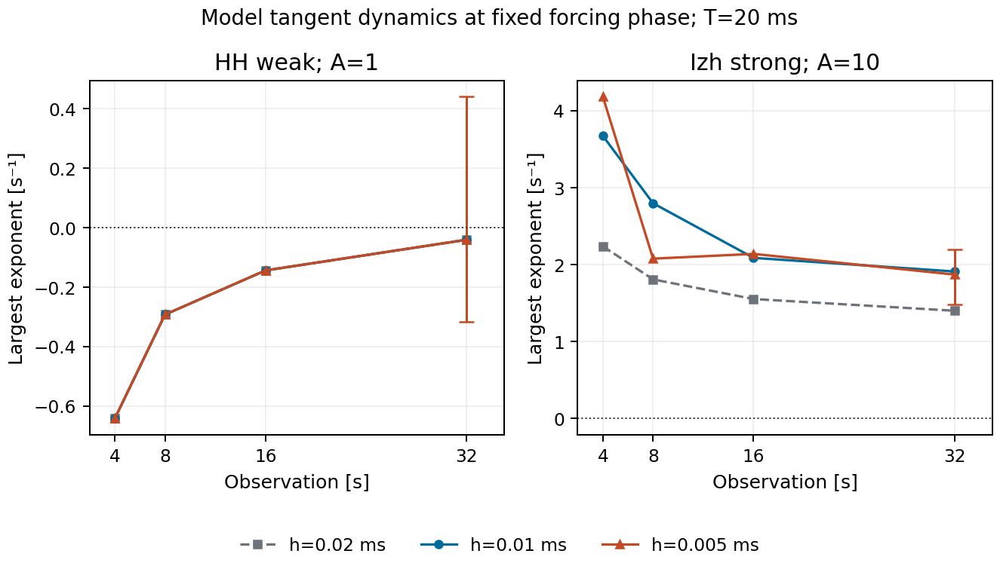

In [47]:
show_figure('optional/figures/forced_lyapunov_convergence.png')

The plotted units are inverse seconds. All 12 long blocks for Izh
strong across three steps are positive; the minimum is 0.000901 inverse ms.
This independently supports a chaotic response at A=10,T=20. Magnitudes still vary
with finite duration and numerical orbit, so an exact limiting exponent is not
claimed. HH weak approaches a near-zero average with both block signs:
quasiperiodicity is plausible, but a very long cycle is not excluded and an
invariant torus is not proved.
Longest-record selected controls at the finest available step:

| signal | h_ms | observation_ms | lambda_max_per_ms | quarter_min_per_ms | quarter_max_per_ms |
| --- | --- | --- | --- | --- | --- |
| HH_DC | 0.01 | 3.2e+04 | -0.0001063 | -0.0004457 | 0.000134 |
| Izh_DC | 0.01 | 3.2e+04 | -5.957e-05 | -0.0005406 | 0.0003926 |
| HH_weak | 0.005 | 3.2e+04 | -4.16e-05 | -0.0003165 | 0.0004394 |
| Izh_weak | 0.01 | 8000 | -0.01553 | -0.01553 | -0.01553 |
| HH_strong | 0.01 | 8000 | -0.1837 | -0.1837 | -0.1837 |
| Izh_strong | 0.005 | 3.2e+04 | 0.00187 | 0.001484 | 0.0022 |

Small finite-time DC deviations from zero partly reflect endpoint phase.
One-period state/tangent maps are independently checked against DOP853:

| model | h_ms | matrix_relative_error | event_time_error_max_ms |
| --- | --- | --- | --- |
| HH | 0.02 | 1.512e-06 | — |
| HH | 0.01 | 9.19e-08 | — |
| HH | 0.005 | 5.688e-09 | — |
| Izh | 0.02 | 7.964e-08 | 2.17e-07 |
| Izh | 0.01 | 6.021e-09 | 1.385e-08 |
| Izh | 0.005 | 4.329e-10 | 8.774e-10 |

The refined Izh orbit agrees with log(spectral radius)/T to 1.64e-10
inverse ms. This validates the tangent solver rather than inferring chaos from
ordinal entropy. See [forced_lyapunov.py](reproducibility/optional/forced_lyapunov.py),
[forced_lyapunov.csv](reproducibility/optional/tables/forced_lyapunov.csv) and
[forced_lyapunov_map_checks.csv](reproducibility/optional/tables/forced_lyapunov_map_checks.csv).

<a id="section-25"></a>

## 5.3.3. Scalar observations of both models

The same inputs A=0,1,10,T=20,J0=10 are analyzed for both models: transient 2000 ms,
observation 8000 ms, dt=0.2 and N=40001. Only membrane potential is passed to
scalar estimators, although all variables are saved. Standardization removes
amplitude scale without changing ordering; the Izh jump is not smoothed.
Independent classifications are:

| signal | classification |
| --- | --- |
| HH_DC | autonomous regular firing; neutral time-shift direction |
| Izh_DC | autonomous regular firing; neutral time-shift direction |
| HH_weak | period <=8 unresolved; near-neutral exponent; quasiperiodicity plausible, unproved |
| Izh_weak | stable stroboscopic period 1T; λ<0 |
| HH_strong | stable stroboscopic period 1T; λ<0 |
| Izh_strong | numerically chaotic: positive model exponent at three steps and in every 8-s block |

In [48]:
dims=csv('dimension_sensitivity.csv',optional=True)
boxes=csv('box_sensitivity.csv',optional=True)
g=dims[(dims.signal=='Izh_strong')&(dims.m==3)&(dims.lag_samples==5)&(dims.W_samples==200)]
g=g[g.N==g.N.max()]
b=boxes[(boxes.signal=='Izh_strong')&(boxes.m==3)]
b=b[b.N==b.N.max()]
display(pd.DataFrame([{'D2_fit':g.estimate.iloc[0],
    'D0_min':b.D0_fit.min(),'D0_max':b.D0_fit.max(),
    'limiting_dimension_consistency':bool(g.estimate.iloc[0]<=b.D0_fit.max())}]))
display(csv('dimension_reliability.csv',optional=True))

,D2_fit,D0_min,D0_max,limiting_dimension_consistency
0,1.287959,1.129088,1.160501,False


,signal,D2_fit,D2_status,D0_raw_m3,D0_raw_dt_ms,D0_status,D0_phase_rich_m3,D0_phase_rich_dt_ms,D0_phase_rich_min,D0_phase_rich_max
0,HH_DC,0.968244,consistent with 1,1.008319,0.2,consistent with 1,NaN,NaN,NaN,NaN
1,Izh_DC,0.998225,consistent with 1,0.981964,0.2,consistent with 1,NaN,NaN,NaN,NaN
2,HH_weak,1.067788,unreliable: no broad plateau,1.392153,0.2,unreliable: parameter sensitivity,NaN,NaN,NaN,NaN
3,Izh_weak,0.931680,finite-scale; 100 observed phases,0.392575,0.2,unreliable: 100 observed phases,0.983812,0.013,0.975360,0.994260
4,HH_strong,1.150234,finite-scale; 100 observed phases,0.325754,0.2,unreliable: 100 observed phases,1.015178,0.013,0.994584,1.032134
5,Izh_strong,1.379035,unreliable: D2>D0,1.144752,0.2,unreliable: D0<D2,NaN,NaN,NaN,NaN


**Selected scalar potential recordings**

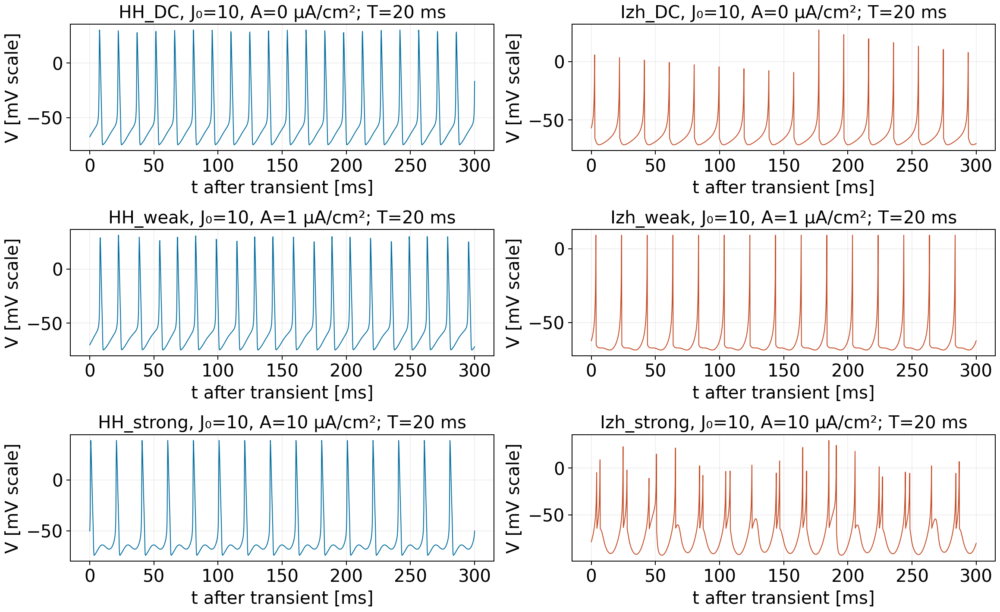

In [49]:
show_figure('optional/figures/selected_traces.png')

**ISI return plots with controlled axes for almost periodic records**

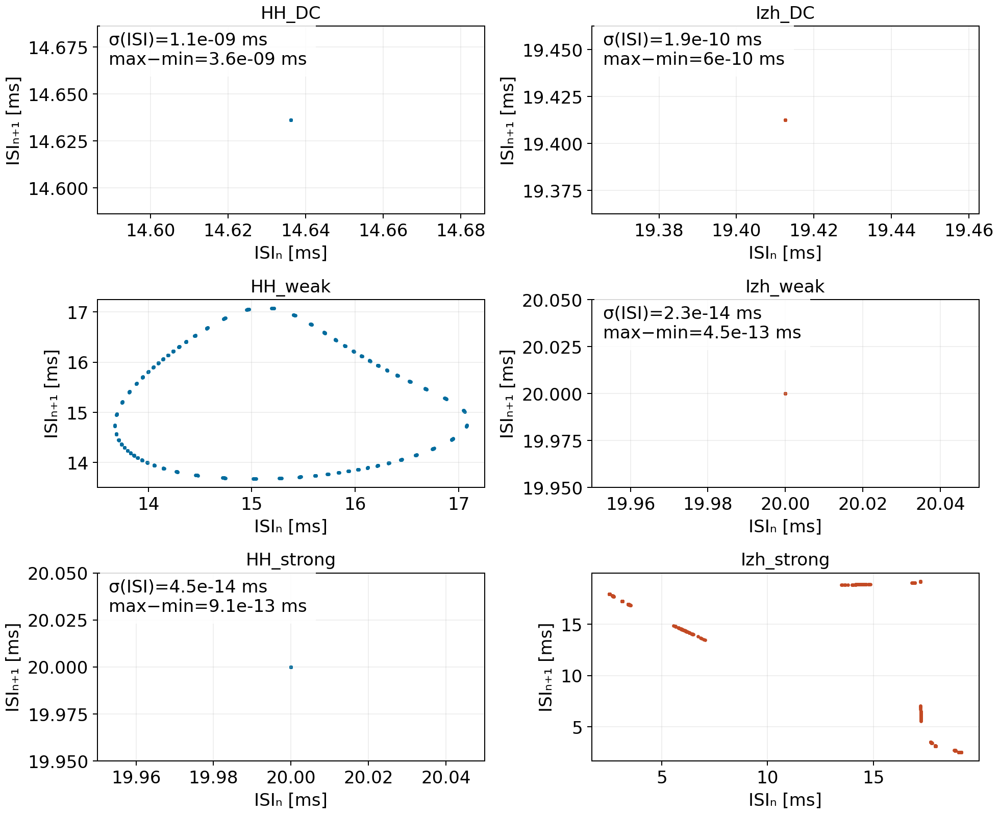

In [50]:
show_figure('optional/figures/ISI_returns.png')

For ISI CV below 1e-4, return axes are fixed around the mean by +/-0.05 ms, with
actual SD and range annotated, preventing numerical jitter from becoming a visible
cloud through autoscaling. At A=0, stroboscopically sampling an autonomous cycle
can trace a curve if its period is incommensurate with T; this does not make the
continuous orbit two-dimensional.

### Reconstruction and comparable delay geometry

ACF uses the first nonpositive lag; MI uses 32 equal-width bins and its first local
minimum. FNN is evaluated at the individual MI lag, Theiler window 40 ms and up to
5000 deterministic reference indices, with ratio thresholds 10 and 2. Nearly
repeated phases and tiny neighbor distances leave residual FNN, including 2-3%
in some regular cases. FNN is a diagnostic rather than an embedding proof for a
hybrid discontinuous observable.

| signal | ACF_first_zero_samples | MI_first_min_samples | ACF_zero_ms | MI_min_ms | FNN_m3 | FNN_m5 |
| --- | --- | --- | --- | --- | --- | --- |
| HH_DC | 10 | 5 | 2 | 1 | 0.0308 | 0.0292 |
| Izh_DC | 18 | 10 | 3.6 | 2 | 0.0238 | 0.0232 |
| HH_weak | 10 | 6 | 2 | 1.2 | 0.0408 | 0.033 |
| Izh_weak | 17 | 3 | 3.4 | 0.6 | 0.27133 | 0.020383 |
| HH_strong | 11 | 11 | 2.2 | 2.2 | 0.070312 | 0.0292 |
| Izh_strong | 25 | 22 | 5 | 4.4 | 0.0602 | 0.0274 |

**ACF and mutual-information diagnostics**

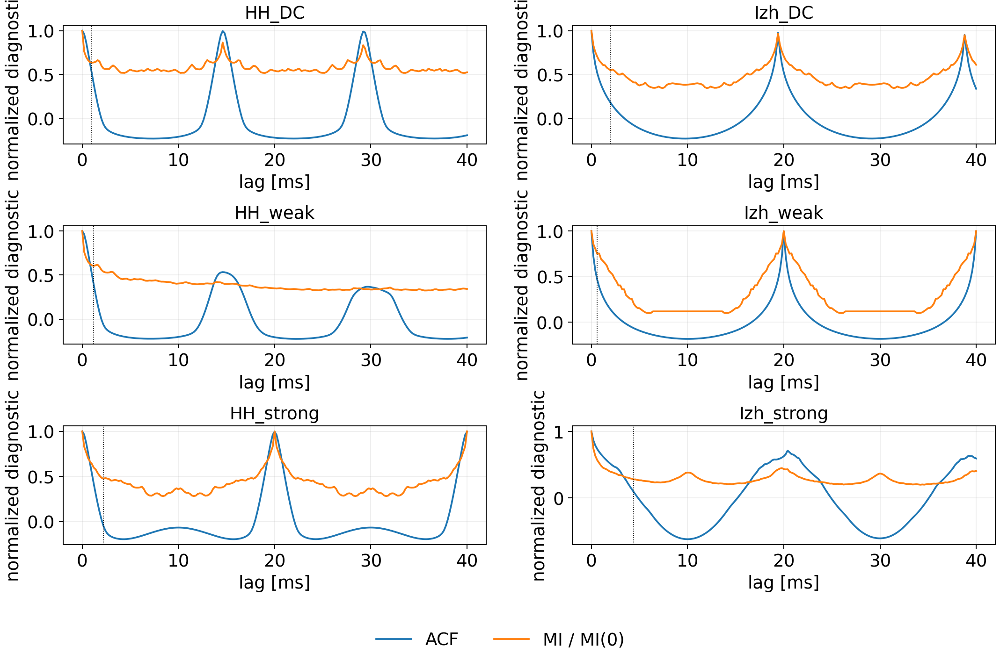

In [51]:
show_figure('optional/figures/delay_diagnostics.png')

**Individual-delay false nearest neighbors**

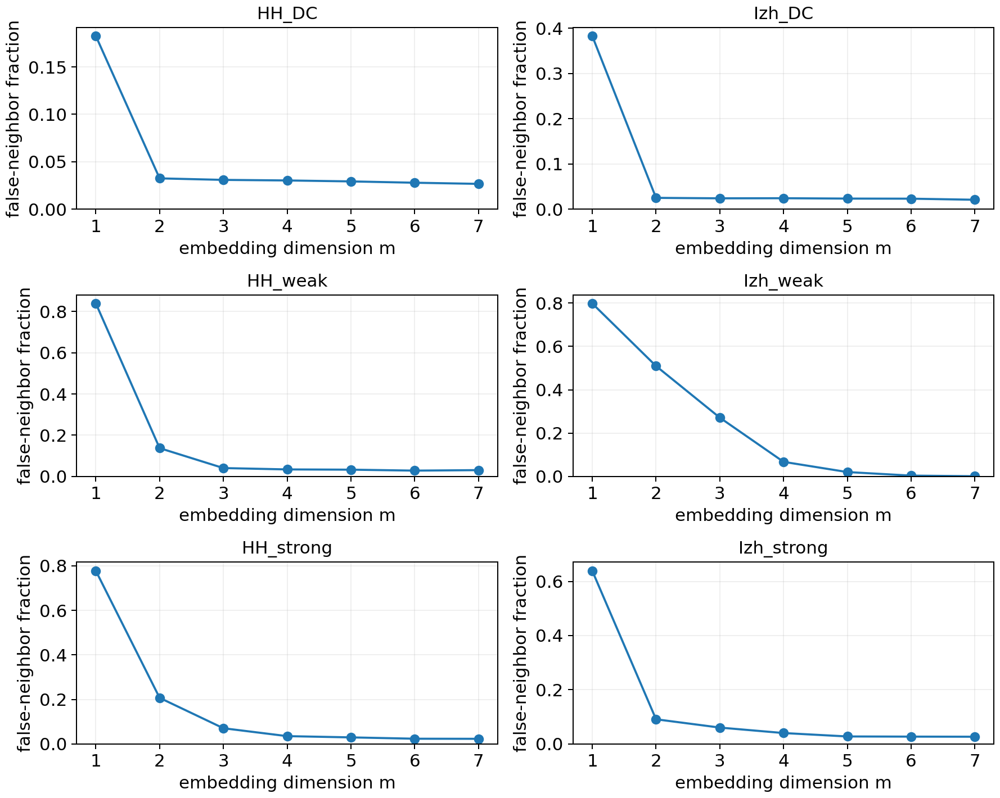

In [52]:
show_figure('optional/figures/FNN_diagnostics.png')

**Scalar delay projections**

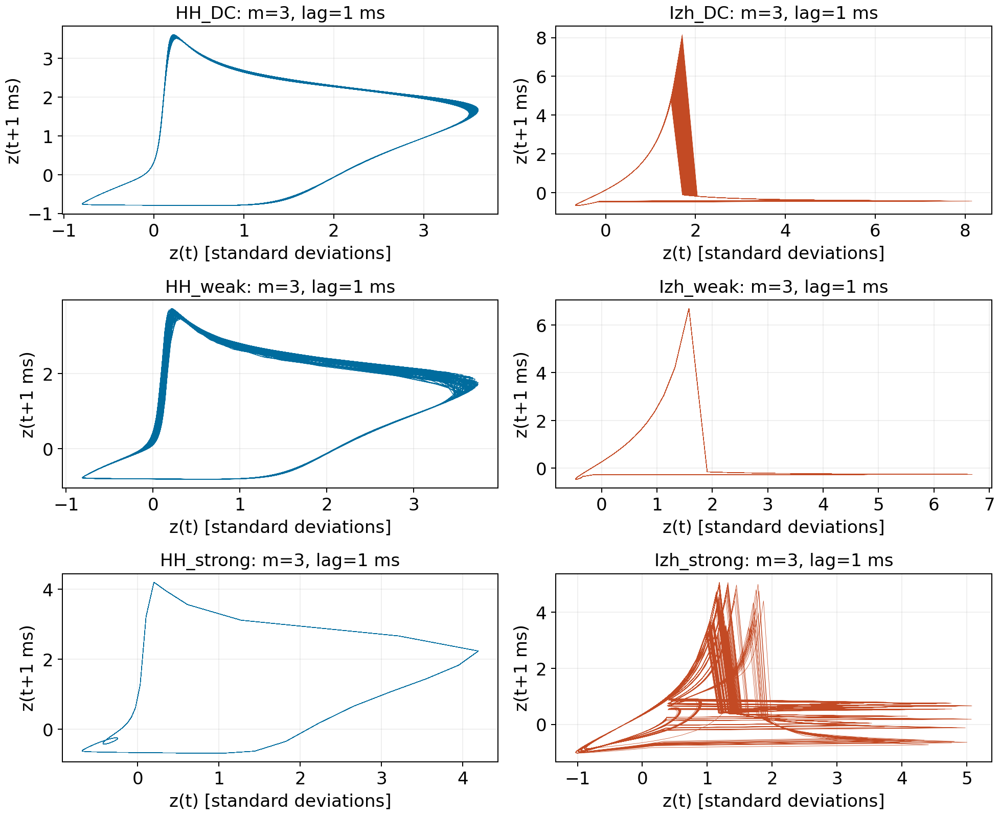

In [53]:
show_figure('optional/figures/reconstruction.png')

The primary comparison fixes physical delay 1 ms (five samples), with individual
MI and 2-ms alternatives. FNN is also evaluated at this same common delay and
at the actual m=4 GP embedding:

| signal | lag_ms | m_GP | FNN_m3 | FNN_m4 | FNN_m5 | FNN_m7 |
| --- | --- | --- | --- | --- | --- | --- |
| HH_DC | 1 | 4 | 0.0308 | 0.0302 | 0.0292 | 0.0266 |
| Izh_DC | 1 | 4 | 0.0072 | 0.0072 | 0.0068 | 0.0072 |
| HH_weak | 1 | 4 | 0.0358 | 0.0296 | 0.027 | 0.0262 |
| Izh_weak | 1 | 4 | 0.095775 | 0.019679 | 0.0060024 | 0.0012 |
| HH_strong | 1 | 4 | 0.060698 | 0.020833 | 0.0106 | 0.0092 |
| Izh_strong | 1 | 4 | 0.0076 | 0.0072 | 0.0086 | 0.0084 |

Residual FNN and scale sensitivity limit geometric interpretation. A common m=4
provides comparable geometry; it is not asserted to be a proven minimal embedding.

### Correlation and capacity estimates

GP uses the same admissible-pair normalization as B, up to 3500 reference vectors,
Theiler window 40 ms, and sensitivity to 0,20,80 ms windows, m=2-6, record length
and delay. The fitting interval r=0.06-0.35 uses standardized Euclidean distance,
at least 200 close pairs, C<0.15 and at least four scales. It is common across
models, rather than chosen for a desired dimension. Local slopes are displayed.

**Correlation sums**

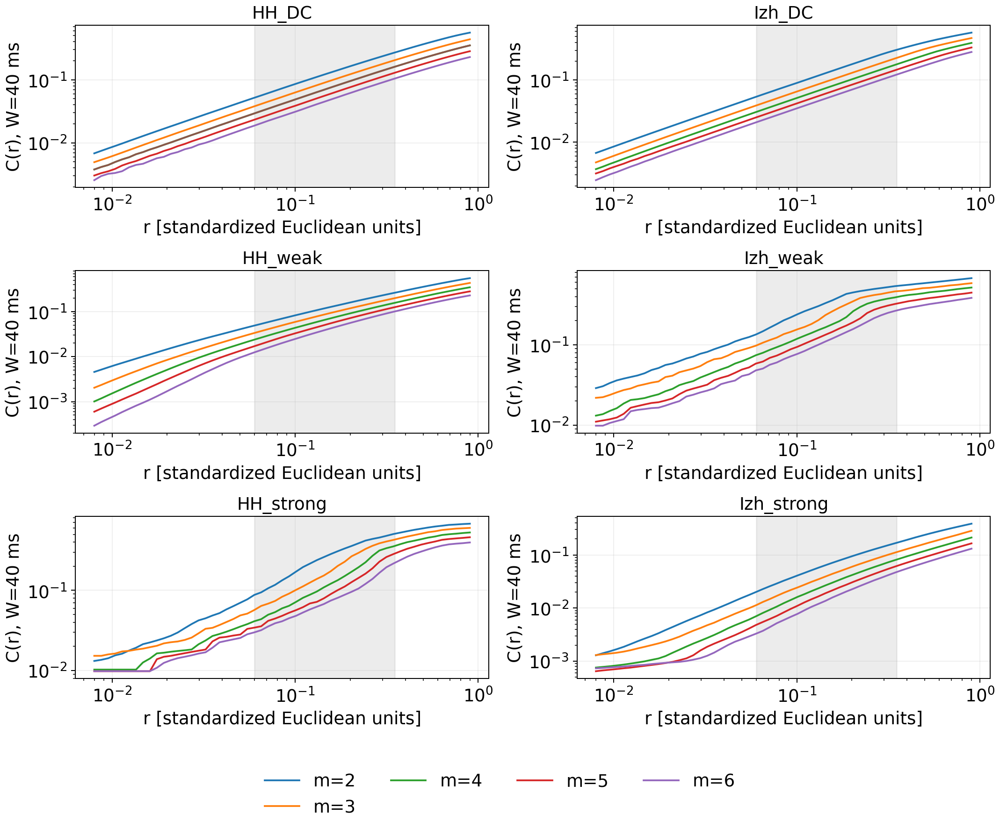

In [54]:
show_figure('optional/figures/correlation_sums.png')

**Local correlation slopes**

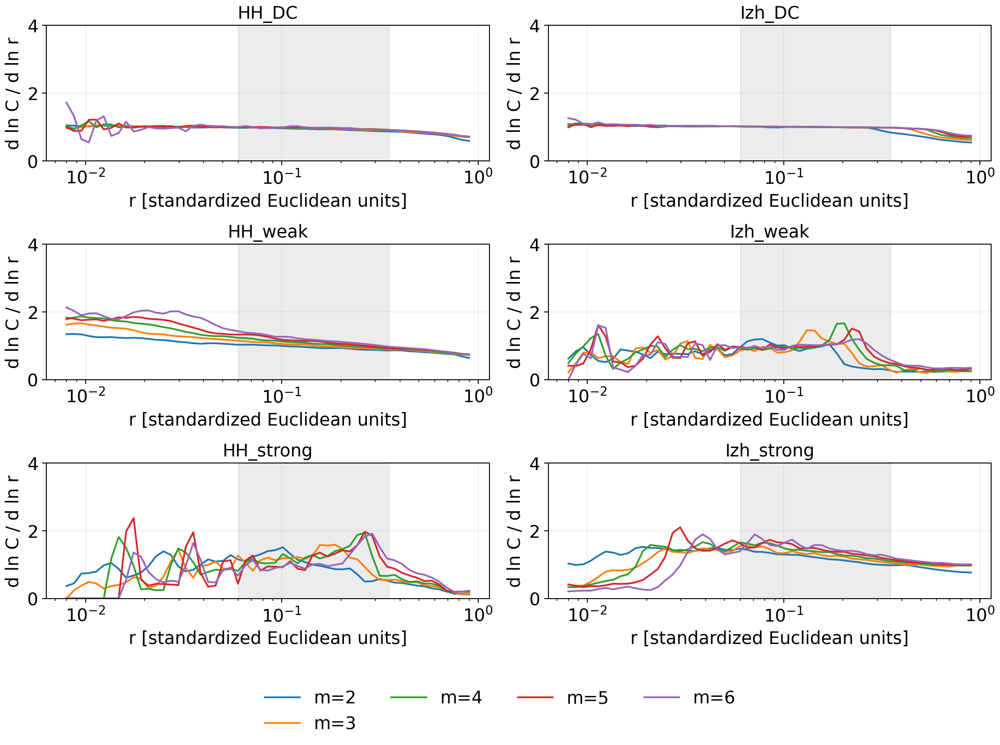

In [55]:
show_figure('optional/figures/correlation_slopes.png')

Box-counting uses epsilon=0.025-0.7, fitting 0.08-0.4 with fewer than N/2 occupied
boxes. Dimensions m=2,3,4, half/full records and four grid offsets are compared.

**Box-counting curves**

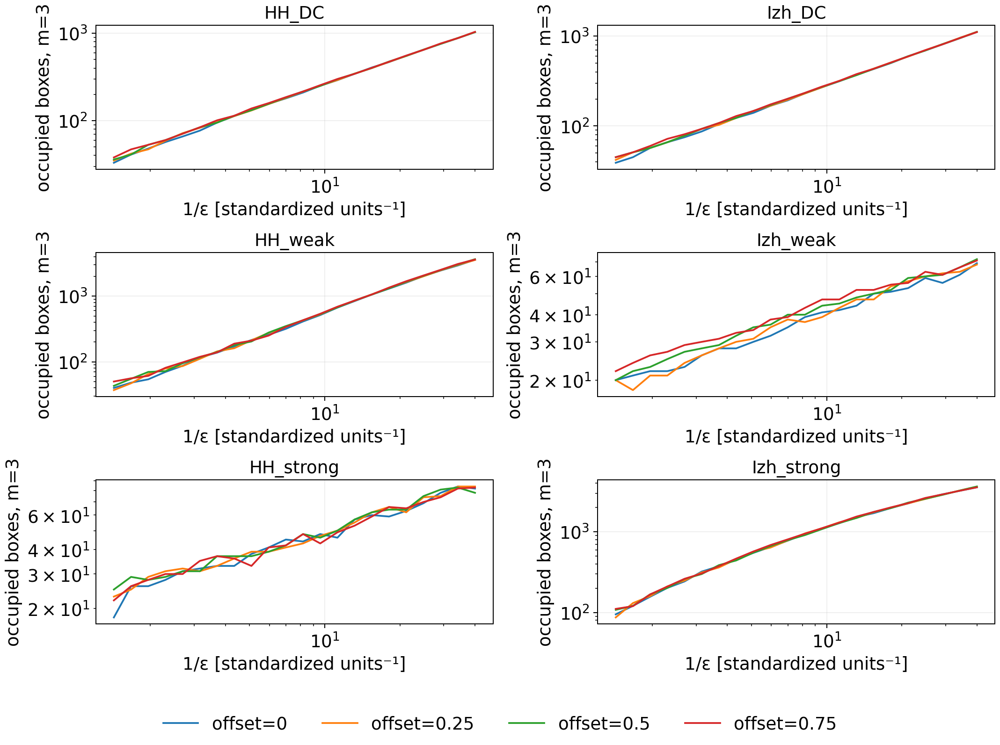

In [56]:
show_figure('optional/figures/box_counts.png')

| signal | rate_Hz | ISI_CV |
| --- | --- | --- |
| HH_DC | 68.324 | 7.2547e-11 |
| Izh_DC | 51.513 | 9.5866e-12 |
| HH_weak | 66.327 | 0.073003 |
| Izh_weak | 50 | 1.1383e-15 |
| HH_strong | 50 | 2.2746e-15 |
| Izh_strong | 85.675 | 0.6008 |

Raw estimates retain explicit reliability labels:

| signal | D2_fit | D2_status | D0_raw_m3 | D0_status |
| --- | --- | --- | --- | --- |
| HH_DC | 0.96824 | consistent with 1 | 1.0083 | consistent with 1 |
| Izh_DC | 0.99823 | consistent with 1 | 0.98196 | consistent with 1 |
| HH_weak | 1.0678 | unreliable: no broad plateau | 1.3922 | unreliable: parameter sensitivity |
| Izh_weak | 0.93168 | finite-scale; 100 observed phases | 0.39257 | unreliable: 100 observed phases |
| HH_strong | 1.1502 | finite-scale; 100 observed phases | 0.32575 | unreliable: 100 observed phases |
| Izh_strong | 1.379 | unreliable: D2>D0 | 1.1448 | unreliable: D0<D2 |

| signal | D2_m3to6_min | D2_m3to6_max | D2_all_settings_min | D2_all_settings_max | D0_all_min | D0_all_max |
| --- | --- | --- | --- | --- | --- | --- |
| HH_DC | 0.96539 | 0.97571 | 0.95748 | 0.97571 | 0.9815 | 1.0428 |
| HH_strong | 0.9986 | 1.1502 | 0.97123 | 1.3109 | 0.27428 | 0.34691 |
| HH_weak | 1.0273 | 1.1757 | 0.98684 | 1.1757 | 1.211 | 1.4946 |
| Izh_DC | 0.99736 | 0.99971 | 0.99087 | 0.99971 | 0.95339 | 1.0069 |
| Izh_strong | 1.288 | 1.5158 | 1.222 | 1.5234 | 0.93984 | 1.3408 |
| Izh_weak | 0.90637 | 0.98115 | 0.82741 | 1.004 | 0.27938 | 0.50403 |

These are sensitivity ranges, not confidence intervals. A smooth periodic orbit
or finite union of reset arcs has dimension 1. A quasiperiodic forced response
could have dimension 2, but that requires independent support. Fractional fit digits
are not asserted as proven fractal dimensions. The model-based classification of
Izh strong does not automatically make its scalar dimension estimate reliable.
For the same Izh-strong m=3,1-ms delay and N=40001, GP gives 1.28796 while
four box fits give 1.12909-1.16050. They cannot simultaneously be limiting dimensions
of the same reconstructed set; the necessary inequality D2<=D0 exposes finite-scale bias.

### Phase aliasing and corrected capacity diagnostics

For locked HH strong and Izh weak, T/dt=100. A perfectly periodic record then
repeats only 100 observed phases however long it is, producing spurious capacity
slopes around 0.33-0.39. These original values are unreliable.
New integrations use dt=0.07,h=0.01,observation 7000 ms (2000 forcing phases), and
dt=0.013,h=0.001,observation 2600 ms (20000 phases), after 2000 ms transient.
Delay remains approximately 1 ms; exact values are retained. All state components
are saved. These are explicitly separate sampling checks, not replacements of the
common primary observation protocol.

| signal | dt_ms | N | actual_lag_ms | D0_m3_offset_mean | D0_min | D0_max | D2_m4 | max_boxes_smallest_eps | distinct_forcing_phases_theoretical |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| HH_strong | 0.2 | 40001 | 1 | 0.32575 | 0.29935 | 0.33745 | 1.1502 | 84 | 100 |
| HH_strong | 0.07 | 100001 | 0.98 | 0.89967 | 0.88587 | 0.91116 | 0.95716 | 600 | 2000 |
| HH_strong | 0.013 | 200001 | 1.001 | 1.0152 | 0.99458 | 1.0321 | 1.1877 | 1153 | 20000 |
| Izh_weak | 0.2 | 40001 | 1 | 0.39257 | 0.37189 | 0.42009 | 0.93168 | 72 | 100 |
| Izh_weak | 0.07 | 100001 | 0.98 | 0.78547 | 0.7662 | 0.80935 | 0.8925 | 469 | 2000 |
| Izh_weak | 0.013 | 200001 | 1.001 | 0.98381 | 0.97536 | 0.99426 | 0.94365 | 1108 | 20000 |

**Phase-sampling aliasing and dimension sensitivity**

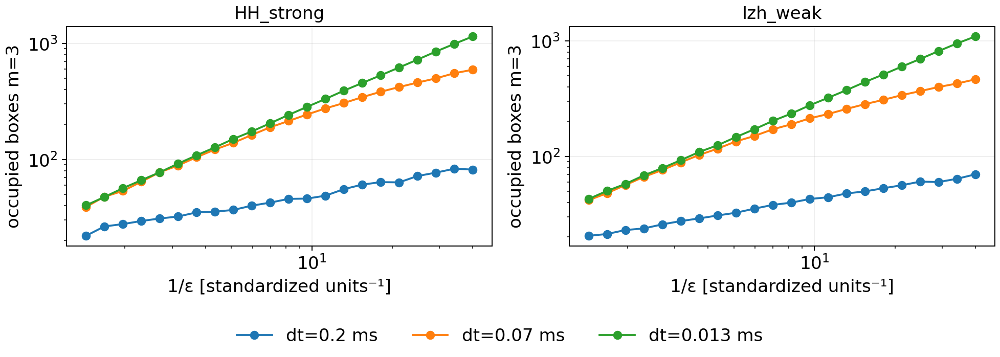

In [57]:
show_figure('optional/figures/sampling_dimension_alias.png')

The finest-sampling summaries are:

| signal | dt_ms | D0_m3_offset_mean | D0_min | D0_max |
| --- | --- | --- | --- | --- |
| HH_strong | 0.013 | 1.0152 | 0.99458 | 1.0321 |
| Izh_weak | 0.013 | 0.98381 | 0.97536 | 0.99426 |

The corrected values support a periodic curve, while grid and scale variation
remain visible. They do not retrospectively validate the original aliased fits.
At fixed dt=0.2, finer integration alone also checks scalar characteristics:

| signal | coarse_h_ms | fine_h_ms | transient_ms | observation_ms | data_file | coarse_events | fine_events | coarse_rate_Hz | fine_rate_Hz | coarse_ISI_CV | fine_ISI_CV | coarse_H | fine_H | coarse_C | fine_C | coarse_D2 | fine_D2 |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| HH_weak | 0.01 | 0.005 | 2000 | 8000 | data/reliability_scalar_HH_A1.00_h0.005.npz | 531 | 531 | 66.327 | 66.327 | 0.073003 | 0.073003 | 0.33044 | 0.33044 | 0.26391 | 0.26391 | 1.0678 | 1.0678 |
| Izh_strong | 0.01 | 0.005 | 2000 | 8000 | data/reliability_scalar_Izh_A10.00_h0.005.npz | 685 | 685 | 85.675 | 85.684 | 0.6008 | 0.60033 | 0.51265 | 0.5126 | 0.34461 | 0.34463 | 1.379 | 1.3798 |

Thus integration error and observation aliasing are kept distinct.

### Entropy-complexity and control recordings

Voltage patterns use ell=4,5, element delays q=1,5,25, sampling dt=0.2,0.4,1 ms
and four consecutive segments. All use the full ell! alphabet, stable temporal
index ties and the same Jensen-Shannon normalization and theoretical bounds as C2.
Primary comparisons use ell=5,q=5,dt=0.2 (physical delay 1 ms). Matched-length
Gaussian, quasiperiodic and shuffled controls are saved with generator states.

| signal | H | H_sd | C | C_sd | patterns_per_possible |
| --- | --- | --- | --- | --- | --- |
| HH_DC | 0.33813 | 0.00070579 | 0.26976 | 0.00050051 | 83.167 |
| HH_strong | 0.54942 | 0 | 0.37892 | 0 | 83.167 |
| HH_weak | 0.33032 | 0.00084547 | 0.26384 | 0.00037584 | 83.167 |
| Izh_DC | 0.31349 | 0.00035435 | 0.25905 | 0.00024669 | 83.167 |
| Izh_strong | 0.51303 | 0.00080138 | 0.34485 | 0.00027083 | 83.167 |
| Izh_weak | 0.44481 | 0 | 0.35326 | 0 | 83.167 |

**Matched neuronal and control recordings with K=120 theoretical bounds**

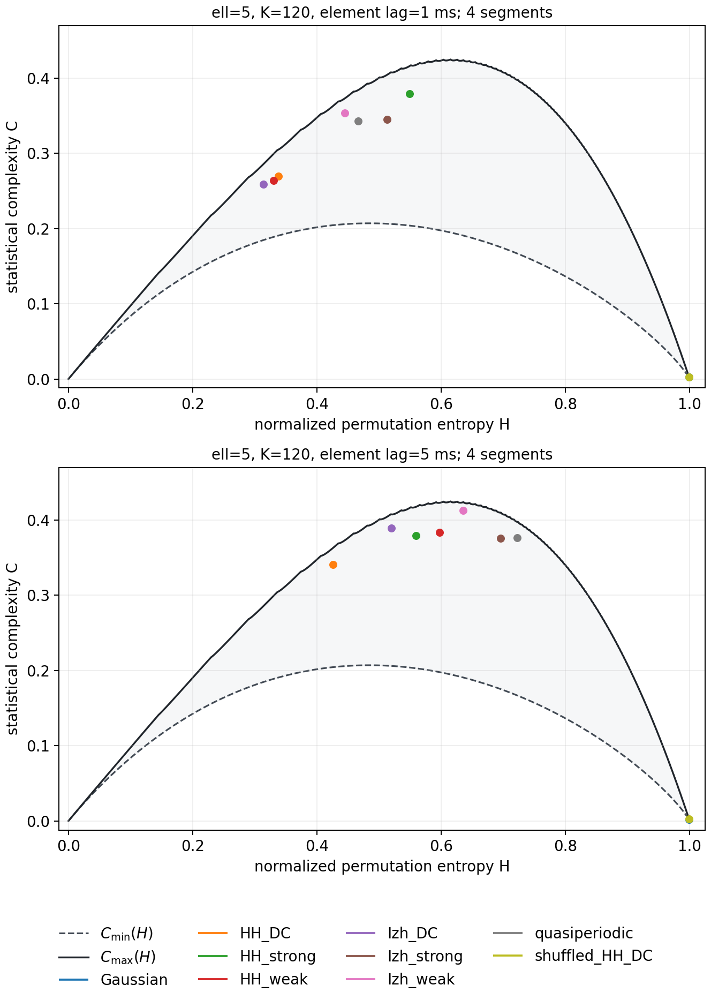

In [58]:
show_figure('optional/figures/HC_with_controls.png')

The main segments have about 83 windows per possible pattern, but dependence and
overlap make this a descriptive count, not proof of negligible bias. Different
potential waveforms, including the Izh reset, can change ordinal statistics even
without different instability. In this set periodic HH strong has higher H at
ell=5,q=5 than chaotic Izh strong: entropy is not monotonic in chaoticity.

### Ordinal structure of interspike intervals

ISI patterns use ell=3,4,5 and consecutive event intervals, not uniform voltage
samples. The table below reports ell=3 at 0.001-ms resolution; the figure compares
ell=3 and ell=5. All three lengths and both resolutions are retained in
`tables/ISI_ordinal.csv`. Almost periodic ISI order can be dominated by numerical event-time jitter.
Both raw intervals and intervals rounded to a stated 0.001-ms resolution are analyzed,
with ties handled deterministically. Rounding is not hidden denoising: the raw
comparison and an event-accuracy check are retained.

| signal | timing_rounding_ms | ell | ISI_count | H | C | patterns | occupied | ties | patterns_per_possible |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| HH_DC | 0.001 | 3 | 546 | 0 | 0 | 544 | 1 | 1 | 90.667 |
| Izh_DC | 0.001 | 3 | 411 | 0 | 0 | 409 | 1 | 1 | 68.167 |
| HH_weak | 0.001 | 3 | 530 | 0.94746 | 0.048761 | 528 | 6 | 0 | 88 |
| Izh_weak | 0.001 | 3 | 399 | 0 | 0 | 397 | 1 | 1 | 66.167 |
| HH_strong | 0.001 | 3 | 399 | 0 | 0 | 397 | 1 | 1 | 66.167 |
| Izh_strong | 0.001 | 3 | 684 | 0.7317 | 0.23679 | 682 | 4 | 0 | 113.67 |

**Raw and explicitly rounded ISI ordinal statistics**

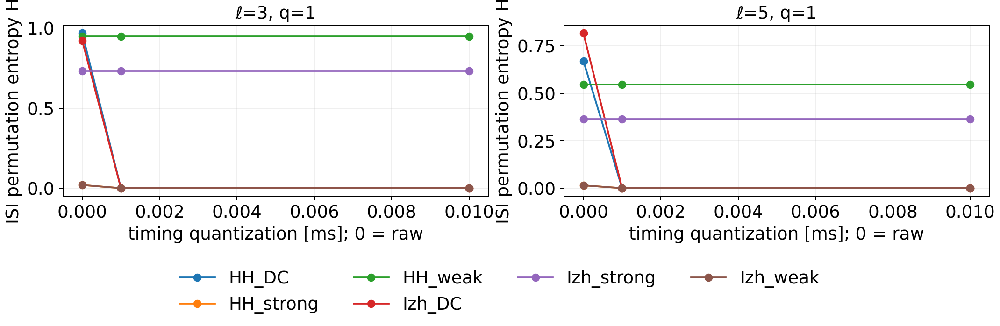

In [59]:
show_figure('optional/figures/ISI_ordinal_resolution.png')

Values for an almost constant train should not be interpreted as dynamical disorder
without inspecting CV, event precision and tie fractions.

<a id="section-26"></a>

## 5.3.4. What is preserved and what is lost

| signal | classification | lambda_max_per_ms | D2_fit | D2_status | D0_raw_m3 | D0_status | D0_phase_rich_m3 | H_ell5_q5 | C_ell5_q5 |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| HH_DC | autonomous regular firing; neutral time-shift direction | -0.00010632 | 0.96824 | consistent with 1 | 1.0083 | consistent with 1 | — | 0.33812 | 0.26975 |
| Izh_DC | autonomous regular firing; neutral time-shift direction | -5.9565e-05 | 0.99823 | consistent with 1 | 0.98196 | consistent with 1 | — | 0.31361 | 0.25914 |
| HH_weak | period <=8 unresolved; near-neutral exponent; quasiperiodicity plausible, unproved | -4.1601e-05 | 1.0678 | unreliable: no broad plateau | 1.3922 | unreliable: parameter sensitivity | — | 0.33044 | 0.26391 |
| Izh_weak | stable stroboscopic period 1T; λ<0 | -0.01553 | 0.93168 | finite-scale; 100 observed phases | 0.39257 | unreliable: 100 observed phases | 0.98381 | 0.44454 | 0.35308 |
| HH_strong | stable stroboscopic period 1T; λ<0 | -0.18367 | 1.1502 | finite-scale; 100 observed phases | 0.32575 | unreliable: 100 observed phases | 1.0152 | 0.54938 | 0.3789 |
| Izh_strong | numerically chaotic: positive model exponent at three steps and in every 8-s block | 0.0018698 | 1.379 | unreliable: D2>D0 | 1.1448 | unreliable: D0<D2 | — | 0.51265 | 0.34461 |

The fixed affine calibration substantially improves HH-rate matching relative to
identity input on both training and held-out currents. It does not simultaneously
preserve low-current silence, sustained-firing threshold and exact f-I rates.
Alternative training constraints expose this tradeoff; impossibility for every
affine criterion is not proved. Under common periodic inputs, locking regions,
spikes per cycle, ISIs and stroboscopic geometry differ. At A=10,T=20, HH is locked
with a negative state-tangent exponent, while Izh has robustly positive finite-time
estimates. The simplification reproduces some regular firing and entrainment
properties of an individual neuron in the tested range, but quantitative threshold,
waveform, frequency and synchronization-boundary prediction needs other calibration
or a more flexible model. Networks and computational-speed benefits were not tested.
Remaining uncertainty includes unresolved periods, finite exponent durations,
nonunique calibration criteria, aliasing, discontinuous observables and unreliable
dimension plateaus. These limitations are not replaced by an ordinal classifier.

In [60]:
display(csv('selected_summary_reliability.csv',optional=True)[
    ['signal','classification','lambda_max_per_ms','D2_status','D0_status']])
print('Network behavior and speedup were not evaluated.')

,signal,classification,lambda_max_per_ms,D2_status,D0_status
0,HH_DC,autonomous regular firing; neutral time-shift ...,-0.000106,consistent with 1,consistent with 1
1,Izh_DC,autonomous regular firing; neutral time-shift ...,-0.000060,consistent with 1,consistent with 1
2,HH_weak,period <=8 unresolved; near-neutral exponent; ...,-0.000042,unreliable: no broad plateau,unreliable: parameter sensitivity
3,Izh_weak,stable stroboscopic period 1T; λ<0,-0.015530,finite-scale; 100 observed phases,unreliable: 100 observed phases
4,HH_strong,stable stroboscopic period 1T; λ<0,-0.183671,finite-scale; 100 observed phases,unreliable: 100 observed phases
5,Izh_strong,numerically chaotic: positive model exponent a...,0.001870,unreliable: D2>D0,unreliable: D0<D2


Network behavior and speedup were not evaluated.


<a id="section-27"></a>

## Supplementary reproducibility and references

`models.py` contains RK4, event splitting and independent DOP853 variational maps.
`run.py` computes calibration, sweeps, refined orbits and scalar comparisons.
`forced_lyapunov.py`, `reliability_checks.py`, `sampling_check.py`,
`threshold_checks.py` and `check_calibration.py` produce the additional evidence.
Raw states, event times and numerical settings are retained alongside the
computed tables. Time is reconstructed as arange(N)*dt_ms
after the transient; forcing phase is fixed by an integer number of transient cycles.
Versions: python 3.11.4 (v3.11.4:d2340ef257, Jun  6 2023, 19:15:51) [Clang 13.0.0 (clang-1300.0.29.30)], numpy 1.26.4, scipy 1.16.3, numba 0.62.1, matplotlib 3.10.8, pandas 2.2.3. Calibration differential evolution uses legacy MT19937 seed 0;
all 624 state words and position are saved, with additional check states in
`data/calibration_check_rng_states.json`. Controls use saved PCG64 states.
Integration, GP reference selection and FNN are deterministic.

- Hodgkin and Huxley (1952), [A quantitative description of membrane current and its application to conduction and excitation in nerve](https://doi.org/10.1113/jphysiol.1952.sp004764), Journal of Physiology 117:500-544. The shifted voltage convention and exact constants are those of the assignment.
- [Izhikevich (2003), Simple model of spiking neurons](https://www.izhikevich.org/publications/spikes.pdf). The prescribed parameters are retained, with event localization more accurate than the illustrative Euler implementation.
- Kong, Payne, Zhu and Johnson (2024), [Saltation Matrices: The Essential Tool for Linearizing Hybrid Dynamical Systems](https://arxiv.org/abs/2306.06862), Proceedings of the IEEE 112:585-608, DOI 10.1109/JPROC.2024.3440211. The applied formula is stated and checked against independent finite differences.
- Reconstruction, FNN, GP, Theiler exclusion and ordinal complexity follow the primary sources listed in the main report and the supplied course definitions.